In [1]:
!pip install albumentations --quiet

In [2]:
import tensorflow as tf
from tensorflow.keras import layers, models, Model, callbacks
from tensorflow.keras.layers import (
    Input, Conv2D, BatchNormalization, Activation, Add,
    MaxPooling2D, UpSampling2D, Concatenate, Multiply, Dropout
)
import os
import numpy as np
import matplotlib.pyplot as plt
import cv2
import albumentations as A
from datetime import datetime
from sklearn.metrics import confusion_matrix
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

# GPU check
print(f"TensorFlow Version: {tf.__version__}")
print(f"GPU Available: {tf.config.list_physical_devices('GPU')}")

2026-06-12 19:22:23.527535: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1781292143.787347      22 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1781292143.858017      22 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1781292144.490871      22 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1781292144.490927      22 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1781292144.490930      22 computation_placer.cc:177] computation placer alr

TensorFlow Version: 2.19.0
GPU Available: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]


In [3]:
def clean_mask_from_path(mask_path, threshold=15, min_area=10):
    # Reads the mask image and cleans noise (pixels that appear black but are not strictly 0)
    # Read the file in grayscale mode
    mask = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE)
    
    if mask is None:
        return None

    # THRESHOLDING: 
    # If a pixel value is below 'threshold' force it to 0.
    # This removes invisible noise caused by image compression (JPEG artifacts).
    _, binary_mask = cv2.threshold(mask, threshold, 255, cv2.THRESH_BINARY)

    # MORPHOLOGICAL CLEANING 
    # Removes isolated single pixels (salt noise) that survived thresholding
    kernel = np.ones((3,3), np.uint8)
    binary_mask = cv2.morphologyEx(binary_mask, cv2.MORPH_OPEN, kernel, iterations=1)

    # AREA FILTERING
    # Analyzes connected white regions. If a region is smaller than 'min_area',
    # it is considered noise/dust and removed, not a real fabric defect.
    num_labels, labels, stats, centroids = cv2.connectedComponentsWithStats(binary_mask, connectivity=8)
    
    cleaned_mask = np.zeros_like(binary_mask)
    
    for i in range(1, num_labels): # 0 is background, start from 1
        area = stats[i, cv2.CC_STAT_AREA]
        if area >= min_area:
            cleaned_mask[labels == i] = 255 

    # Normalize to 0.0 and 1.0 (float32) for the Neural Network
    return (cleaned_mask > 0).astype(np.float32)

In [4]:
class Config:
    DATA_PATH = ""  
    
    # Image settings
    ORIG_WIDTH = 4096
    ORIG_HEIGHT = 256
    PATCH_SIZE = 256
    
    # Training settings
    BATCH_SIZE = 16  
    EPOCHS = 200     
    LEARNING_RATE = 1e-4
    
    # Data balance settings 
    PATCHES_PER_IMAGE = 16  # Number of patches to extract from each image
    DEFECT_PATCH_RATIO = 0.75  # 75% of patches will be defect-centered
    MIN_DEFECT_PIXELS = 10  # At least 500 pixels should be defect
    
    # Augmentation
    AUGMENT_PROB = 0.8
    
    MASK_THRESHOLD = 0

# Automatically find dataset path
for root, dirs, files in os.walk("/kaggle/input"):
    if "train" in dirs and "val" in dirs:
        Config.DATA_PATH = root
        print(f"Dataset found: {Config.DATA_PATH}")
        break

if not Config.DATA_PATH:
    print("WARNING: Dataset not found. Please check /kaggle/input")

Dataset found: /kaggle/input/aitex-dataset/aitex_dataset_processed


In [5]:
import os
import cv2
import numpy as np
import glob

def terminate_bad_files():
    """
    Scans all mask files in the dataset to identify corrupted or incorrectly labeled files.
    Returns a list of filenames to be excluded from training.
    """
    if not Config.DATA_PATH:
        print("ERROR: Config.DATA_PATH is not set.")
        return []

    dirs_to_check = [
        os.path.join(Config.DATA_PATH, "train", "masks"),
        os.path.join(Config.DATA_PATH, "val", "masks")
    ]
    
    bad_files_list = []
    total_scanned = 0
    
    for mask_dir in dirs_to_check:
        if not os.path.exists(mask_dir):
            print(f"Directory not found: {mask_dir}")
            continue
            
        mask_files = glob.glob(os.path.join(mask_dir, "*.png"))
        print(f"Found {len(mask_files)} files in {mask_dir}. Starting analysis...")
        
        for mask_path in mask_files:
            total_scanned += 1
            filename = os.path.basename(mask_path)
            
            # Read the mask
            mask = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE)
            if mask is None: continue
            
            # Noise Thresholding
            # Ignore pixels with value < 50 (sensor noise)
            _, binary_mask = cv2.threshold(mask, 50, 255, cv2.THRESH_BINARY)
            defect_pixels = np.sum(binary_mask > 0)
            
            # Corruption Criteria
            # If a mask has > 2000 defect pixels, it is likely a corrupted file
            # Real defects in this dataset are usually thin scratches or small holes.
            
            if defect_pixels > 2000:
                print(f"CORRUPT FILE DETECTED: {filename} (Pixel Count: {defect_pixels})")
                
                # Convert mask filename to original image filename for the blacklist
                # '0103_002_mask.png' -> '0103_002.png'
                clean_name = filename.replace("_mask.png", ".png")
                
                if clean_name not in bad_files_list:
                    bad_files_list.append(clean_name)
                    
            elif 0 < defect_pixels < 50:
                 # Small noise, will be handled by the cleaning function later
                 pass

    print(f"Scanned {total_scanned} files.")
    print(f"FOUND {len(bad_files_list)} CORRUPT FILES.")
    
    print("BLACKLIST = [")
    for f in sorted(bad_files_list):
        print(f"    '{f}',")
    print("]")
    
    return bad_files_list

full_blacklist = terminate_bad_files()

Found 82 files in /kaggle/input/aitex-dataset/aitex_dataset_processed/train/masks. Starting analysis...
CORRUPT FILE DETECTED: 0073_010_03_mask.png (Pixel Count: 4796)
CORRUPT FILE DETECTED: 0072_010_03_mask.png (Pixel Count: 2534)
CORRUPT FILE DETECTED: 0075_010_03_mask.png (Pixel Count: 16072)
CORRUPT FILE DETECTED: 0074_010_03_mask.png (Pixel Count: 3029)
CORRUPT FILE DETECTED: 0010_006_02_mask.png (Pixel Count: 2170)
CORRUPT FILE DETECTED: 0103_010_03_mask.png (Pixel Count: 143220)
CORRUPT FILE DETECTED: 0011_006_02_mask.png (Pixel Count: 2149)
CORRUPT FILE DETECTED: 0102_010_03_mask.png (Pixel Count: 30545)
CORRUPT FILE DETECTED: 0016_006_02_mask.png (Pixel Count: 2285)
CORRUPT FILE DETECTED: 0081_006_04_mask.png (Pixel Count: 4078)
CORRUPT FILE DETECTED: 0105_010_03_mask.png (Pixel Count: 5488)
CORRUPT FILE DETECTED: 0095_010_03_mask.png (Pixel Count: 9481)
Found 20 files in /kaggle/input/aitex-dataset/aitex_dataset_processed/val/masks. Starting analysis...
CORRUPT FILE DETECTED:

In [6]:
train_image_dir = os.path.join(Config.DATA_PATH, "train", "images")
train_mask_dir = os.path.join(Config.DATA_PATH, "train", "masks")
val_image_dir = os.path.join(Config.DATA_PATH, "val", "images")
val_mask_dir = os.path.join(Config.DATA_PATH, "val", "masks")

# Filter valid train pairs
valid_train_mask_files = [f for f in os.listdir(train_mask_dir) if f.endswith('.png')]
train_image_mask_pairs = []
for mask_file in valid_train_mask_files:
    image_file = mask_file.replace('_mask.png', '.png')
    image_path = os.path.join(train_image_dir, image_file)
    mask_path = os.path.join(train_mask_dir, mask_file)
    if os.path.exists(image_path):
        train_image_mask_pairs.append((image_path, mask_path))

# Filter valid val pairs
valid_val_mask_files = [f for f in os.listdir(val_mask_dir) if f.endswith('.png')]
val_image_mask_pairs = []
for mask_file in valid_val_mask_files:
    image_file = mask_file.replace('_mask.png', '.png')
    image_path = os.path.join(val_image_dir, image_file)
    mask_path = os.path.join(val_mask_dir, mask_file)
    if os.path.exists(image_path):
        val_image_mask_pairs.append((image_path, mask_path))

# Split into separate lists
train_images = [pair[0] for pair in train_image_mask_pairs]
train_masks = [pair[1] for pair in train_image_mask_pairs]
val_images = [pair[0] for pair in val_image_mask_pairs]
val_masks = [pair[1] for pair in val_image_mask_pairs]

print(f"Training pairs: {len(train_images)}")
print(f"Validation pairs: {len(val_images)}")

Training pairs: 82
Validation pairs: 20


In [7]:
def extract_defect_centered_patches(image, mask, config=Config):
    h, w = image.shape[:2]
    patch_size = config.PATCH_SIZE
    num_patches = config.PATCHES_PER_IMAGE
    defect_ratio = config.DEFECT_PATCH_RATIO
    
    patches_img = []
    patches_mask = []
    is_defect = []
    
    # Identify where the defects are located
    # We use mask > 0 to catch even faint defects.
    defect_coords = np.argwhere(mask > 0)
    has_defects = len(defect_coords) > 0
    
    if has_defects:
        # Forced Defect Sampling 
        num_defect_patches = int(num_patches * defect_ratio)
        
        for _ in range(num_defect_patches):
            # Pick a random defect pixel to be the center of our new patch
            center_idx = np.random.randint(len(defect_coords))
            center_y, center_x = defect_coords[center_idx]
            
            # Calculate patch boundaries, ensuring we don't go outside the image
            y_start = max(0, min(center_y - patch_size // 2, h - patch_size))
            x_start = max(0, min(center_x - patch_size // 2, w - patch_size))
            
            # Crop the image and the mask
            patch_img = image[y_start:y_start + patch_size, 
                            x_start:x_start + patch_size]
            patch_mask = mask[y_start:y_start + patch_size,
                            x_start:x_start + patch_size]
            
            # Only keep this patch if it actually contains enough defect pixels.
            # Sometimes a crop on the edge of a defect might miss the defect itself.
            if np.sum(patch_mask > 0) >= config.MIN_DEFECT_PIXELS:
                patches_img.append(patch_img)
                patches_mask.append(patch_mask)
                is_defect.append(True)
    
    # Random Background Sampling (for context)
    # We fill the rest of the batch (e.g., 25%) with random crops.
    # This teaches the model what "clean" fabric looks like
    num_random = int(num_patches * (1 - defect_ratio)) if has_defects else num_patches
    
    for _ in range(num_random):
        y_start = np.random.randint(0, max(1, h - patch_size))
        x_start = np.random.randint(0, max(1, w - patch_size))
        
        patch_img = image[y_start:y_start + patch_size,
                          x_start:x_start + patch_size]
        patch_mask = mask[y_start:y_start + patch_size,
                          x_start:x_start + patch_size]
        
        patches_img.append(patch_img)
        patches_mask.append(patch_mask)
        # Check if we accidentally cropped a defect in random mode
        is_defect.append(np.sum(patch_mask > 0) >= config.MIN_DEFECT_PIXELS)
    
    return patches_img, patches_mask, is_defect

In [8]:
def get_augmentation_pipeline(mode='train'):
    if mode == 'train':
        return A.Compose([
            A.HorizontalFlip(p=0.5),
            A.VerticalFlip(p=0.5),
            A.Rotate(limit=15, border_mode=cv2.BORDER_CONSTANT, value=0, p=0.3),
            A.ShiftScaleRotate(
                shift_limit=0.0625, 
                scale_limit=0.1,
                rotate_limit=10,
                border_mode=cv2.BORDER_CONSTANT, # (value=0) to fill empty space with black
                value=0,
                p=0.3
            ),
            
            A.RandomBrightnessContrast(
                brightness_limit=0.2,
                contrast_limit=0.2,
                p=0.5
            ),
            A.GaussNoise(var_limit=(10.0, 30.0), p=0.3),
            A.GaussianBlur(blur_limit=(3, 5), p=0.2),
            
            A.ElasticTransform(
                alpha=1,
                sigma=20,
                alpha_affine=20,
                border_mode=cv2.BORDER_CONSTANT,
                value=0,
                p=0.3
            ),
            
            A.OneOf([
                A.GridDistortion(border_mode=cv2.BORDER_CONSTANT, value=0, p=1.0),
                A.OpticalDistortion(distort_limit=0.05, shift_limit=0.05,
                                   border_mode=cv2.BORDER_CONSTANT, value=0, p=1.0),
            ], p=0.2),
        ], additional_targets={'mask': 'mask'}) #apply the same changes to mask
    else:
        return None

In [9]:
@tf.function
def focal_loss(y_true, y_pred, alpha=0.25, gamma=2.0):
    # FL = -α(1-p)^γ log(p)        y=1 (defect)
    # FL = -(1-α)p^γ log(1-p)      y=0 (background)
    
    y_pred = tf.clip_by_value(y_pred, 1e-7, 1.0 - 1e-7)
    
    # positive classes (defects)
    focal_pos = -alpha * tf.pow(1.0 - y_pred, gamma) * y_true * tf.math.log(y_pred)
    
    # negative classes (background)
    focal_neg = -(1.0 - alpha) * tf.pow(y_pred, gamma) * (1.0 - y_true) * tf.math.log(1.0 - y_pred)
    
    focal = focal_pos + focal_neg
    
    return tf.reduce_mean(focal)

@tf.function
def dice_loss(y_true, y_pred, smooth=1e-6):
    """
    The Dice coefficient measures the intersection/union ratio. 
    It works well with unbalanced datasets because it is proportional.
    
    Dice = 2 * |A ∩ B| / (|A| + |B|)
    """
    y_true_f = tf.reshape(y_true, [-1])
    y_pred_f = tf.reshape(y_pred, [-1])
    
    intersection = tf.reduce_sum(y_true_f * y_pred_f)
    union = tf.reduce_sum(y_true_f) + tf.reduce_sum(y_pred_f)
    
    dice = (2.0 * intersection + smooth) / (union + smooth)
    
    return 1.0 - dice

@tf.function
def combined_loss(y_true, y_pred):
    """
    Combine loss: Focal + Dice
    
    Focal Loss: It resolves class inequality.
    Dice Loss: Measures segmentation quality.
    
    These two methods provide both balanced learning and good segmentation.
    """
    focal = focal_loss(y_true, y_pred, alpha=0.25, gamma=2.0)
    dice = dice_loss(y_true, y_pred)
    
    return 0.5 * focal + 0.5 * dice

In [10]:
def conv_block(x, filters, kernel_size=3, activation='relu', use_bn=True, dropout=0.0):
    """
    Standard convolutional block: Conv -> BN -> ReLU -> Conv -> BN -> ReLU
    """
    x = Conv2D(filters, kernel_size, padding='same')(x)
    if use_bn:
        x = BatchNormalization()(x)
    x = Activation(activation)(x)
    if dropout > 0:
        x = Dropout(dropout)(x)

    x = Conv2D(filters, kernel_size, padding='same')(x)
    if use_bn:
        x = BatchNormalization()(x)
    x = Activation(activation)(x)

    return x

def attention_gate(x, g, filters):
    """
    Attention Gate - Learns what to focus on in the skip connection of the decoder.

    Args:
        x: Skip connection from encoder (high resolution)
        g: Gating signal from decoder (low resolution, semantic)
        filters: Number of attention filters
    """
    # Transform skip connection
    theta_x = Conv2D(filters, kernel_size=1, padding='same')(x)  # No strides=2

    # Transform gating signal
    phi_g = Conv2D(filters, kernel_size=1, padding='same')(g)

    # Combine and activate
    concat = Add()([theta_x, phi_g])
    relu = Activation('relu')(concat)

    # Generate attention coefficients (between 0-1)
    psi = Conv2D(1, kernel_size=1, padding='same')(relu)
    psi = Activation('sigmoid')(psi)

    # Apply attention: important regions close to 1, unimportant close to 0
    output = Multiply()([x, psi])

    return output

In [11]:
def build_attention_unet(input_shape=(256, 256, 1), filters_base=32):
    """
    Constructs the Attention U-Net model.

    Architecture Overview:
    1. Encoder (Left side): Extracts features, reducing spatial size but increasing depth.
    2. Bottleneck (Bottom): Captures the most abstract/high-level representation.
    3. Decoder (Right side): Reconstructs the image size using UpSampling.
    4. Attention Gates: Filters the skip connections to suppress noise before merging.
    """
    inputs = Input(input_shape)

    # ENCODER (Downsampling Path)
    # Level 1: 256x256 -> 128x128
    conv1 = conv_block(inputs, filters_base, dropout=0.1)
    pool1 = MaxPooling2D((2, 2))(conv1)

    # Level 2: 128x128 -> 64x64
    conv2 = conv_block(pool1, filters_base * 2, dropout=0.1)
    pool2 = MaxPooling2D((2, 2))(conv2)

    # Level 3: 64x64 -> 32x32
    conv3 = conv_block(pool2, filters_base * 4, dropout=0.2)
    pool3 = MaxPooling2D((2, 2))(conv3)

    # Level 4: 32x32 -> 16x16
    conv4 = conv_block(pool3, filters_base * 8, dropout=0.2)
    pool4 = MaxPooling2D((2, 2))(conv4)

    # BOTTLENECK (The Bridge)
    # Level 5: 16x16. deepest layer, highest abstraction
    conv5 = conv_block(pool4, filters_base * 16, dropout=0.3)

    # DECODER (Upsampling Path with Attention) 
    
    # Level 4 Reconstruction: 16x16 -> 32x32
    # We use Bilinear Interpolation for smoother upsampling (prevents checkerboard artifacts)
    up6 = UpSampling2D(size=(2, 2), interpolation='bilinear')(conv5)
    # ATTENTION GATE: Filters the skip connection (conv4) using the decoder signal (up6)
    att6 = attention_gate(x=conv4, g=up6, filters=filters_base * 8)
    merge6 = Concatenate()([up6, att6])
    conv6 = conv_block(merge6, filters_base * 8, dropout=0.2)

    # Level 3 Reconstruction: 32x32 -> 64x64
    up7 = UpSampling2D(size=(2, 2), interpolation='bilinear')(conv6)
    att7 = attention_gate(x=conv3, g=up7, filters=filters_base * 4)
    merge7 = Concatenate()([up7, att7])
    conv7 = conv_block(merge7, filters_base * 4, dropout=0.2)

    # Level 2 Reconstruction: 64x64 -> 128x128
    up8 = UpSampling2D(size=(2, 2), interpolation='bilinear')(conv7)
    att8 = attention_gate(x=conv2, g=up8, filters=filters_base * 2)
    merge8 = Concatenate()([up8, att8])
    conv8 = conv_block(merge8, filters_base * 2, dropout=0.1)

    # Level 1 Reconstruction: 128x128 -> 256x256
    up9 = UpSampling2D(size=(2, 2), interpolation='bilinear')(conv8)
    att9 = attention_gate(x=conv1, g=up9, filters=filters_base)
    merge9 = Concatenate()([up9, att9])
    conv9 = conv_block(merge9, filters_base, dropout=0.1)

    # OUTPUT LAYER
    # 1 Filter: Because we want a binary mask (Defect vs Background)
    # Sigmoid: Squashes output between 0.0 and 1.0 (Probability)
    outputs = Conv2D(1, kernel_size=1, activation='sigmoid', name='output')(conv9)

    model = Model(inputs=[inputs], outputs=[outputs], name='Attention_UNet')

    return model

In [12]:
def build_hrnet(input_shape=(256, 256, 1), base_filters=32):
    """
    Simplified HRNet encoder-decoder for segmentation.
    Note: This is not a full HRNet, but a basic multi-resolution block.
    """
    inputs = Input(input_shape)

    # Stage 1
    x1 = conv_block(inputs, base_filters)
    p1 = MaxPooling2D((2, 2))(x1)

    # Stage 2
    x2 = conv_block(p1, base_filters * 2)
    p2 = MaxPooling2D((2, 2))(x2)

    # Stage 3
    x3 = conv_block(p2, base_filters * 4)
    p3 = MaxPooling2D((2, 2))(x3)

    # Stage 4
    x4 = conv_block(p3, base_filters * 8)

    # Multi-resolution fusion (simple upsampling and concatenation)
    u3 = UpSampling2D((2, 2), interpolation='bilinear')(x4)
    f3 = Concatenate()([u3, x3])

    u2 = UpSampling2D((2, 2), interpolation='bilinear')(f3)
    f2 = Concatenate()([u2, x2])

    u1 = UpSampling2D((2, 2), interpolation='bilinear')(f2)
    f1 = Concatenate()([u1, x1])

    outputs = Conv2D(1, (1, 1), activation='sigmoid')(f1)

    model = Model(inputs, outputs, name='HRNet_Simple')
    return model

In [13]:
import os
import cv2
import numpy as np

class AITexDataset:
    def __init__(self, image_paths, mask_paths, config=Config, mode='train', ignore_list=None):
        self.image_paths = image_paths
        self.mask_paths = mask_paths
        self.config = config
        self.mode = mode
        
        # BLACKLIST MANAGEMENT
        # Normalize the ignore list to avoid matching errors 
        if ignore_list:
            self.ignore_list = [str(x).strip() for x in ignore_list]
        else:
            self.ignore_list = []
            
        # Initialize Augmentation Pipeline (only if it exists and we are in training mode)
        self.augmentation = get_augmentation_pipeline(mode) if 'get_augmentation_pipeline' in globals() else None
        
        self.patches = []
        self.labels = []
        
        self._extract_all_patches()
    
    def _extract_all_patches(self):
        print(f"EXTRACTING PATCHES ({self.mode.upper()}) - FILTERING ACTIVE")
        print(f"Blacklist Size: {len(self.ignore_list)} files")
        
        ignored_count = 0
        
        for idx, (img_path, mask_path) in enumerate(zip(self.image_paths, self.mask_paths)):
            filename = os.path.basename(img_path).strip()
            
            # AGGRESSIVE FILTERING LOGIC
            # Check if the filename contains any blacklisted root name
            should_ignore = False
            
            for bad_name in self.ignore_list:
                # Remove extension to match loosely (e.g., "file.png" matches "file_copy.png")
                bad_root = bad_name.replace(".png", "")
                
                if bad_root in filename:
                    should_ignore = True
                    # Debug print for critical files
                    if "0103_010_03" in filename:
                        print(f"BLOCKED: '{filename}' (Matched blacklist item: '{bad_name}')")
                    break
            
            if should_ignore:
                ignored_count += 1
                continue
                
            image = cv2.imread(img_path, cv2.IMREAD_GRAYSCALE)
            
            # Use custom cleaning function (Threshold=50 eliminates noise)
            mask = clean_mask_from_path(mask_path, threshold=50, min_area=20) 
            
            if image is None or mask is None: continue

            # Normalize Image (0-255 -> 0.0-1.0)
            image = image.astype(np.float32) / 255.0
            
            # Extract patches using the Defect-Centered Strategy
            patches_img, patches_mask, is_defect = extract_defect_centered_patches(image, mask, self.config)
            
            for p_img, p_mask, defect_flag in zip(patches_img, patches_mask, is_defect):
                self.patches.append({
                    'image': p_img,
                    'mask': p_mask,
                    'is_defect': defect_flag,
                    'source_file': filename 
                })
                self.labels.append(1 if defect_flag else 0)
            
            if (idx + 1) % 50 == 0: print(f"Processed: {idx + 1} images...")
            
        print(f"\nBlocked {ignored_count} corrupt files/copies.")

    def __len__(self): return len(self.patches)
    
    def get_item(self, idx):
        """
        Returns a single sample (Image + Mask) for the model.
        """
        patch = self.patches[idx]
        image = patch['image'].copy()
        mask = patch['mask'].copy()
        
        # Apply Augmentation (Flip, Rotate, Noise) if in Training Mode
        if self.augmentation and self.mode == 'train':
            augmented = self.augmentation(image=image, mask=mask)
            image = augmented['image']
            mask = augmented['mask']

        # Ensure mask is strictly 0.0 or 1.0
        mask = (mask > 0).astype(np.float32)
            
        # Add channel dimension (H, W) -> (H, W, 1) for TensorFlow
        image = np.expand_dims(image, axis=-1)
        mask = np.expand_dims(mask, axis=-1)
        
        return image.astype(np.float32), mask.astype(np.float32)


# INITIALIZE DATASETS

# Ensure we have the blacklist from the previous step
# If Cell 5 was not run, we define the critical list manually here as a fallback
if 'full_blacklist' not in globals():
    BLACKLIST = [
        '0004_002_01.png', '0005_002_01.png', '0010_006_02.png', '0011_006_02.png', 
        '0016_006_02.png', '0072_010_03.png', '0073_010_03.png', '0074_010_03.png', 
        '0075_010_03.png', '0080_036_01.png', '0081_006_04.png', '0095_010_03.png', 
        '0102_010_03.png', '0103_010_03.png', '0105_010_03.png'
    ]
else:
    BLACKLIST = full_blacklist

print("Initializing Training Dataset...")
train_dataset_obj = AITexDataset(train_images, train_masks, Config, mode='train', ignore_list=BLACKLIST)

print("Initializing Validation Dataset...")
val_dataset_obj = AITexDataset(val_images, val_masks, Config, mode='val', ignore_list=BLACKLIST)

print("\nVerifying Data Integrity...")
leak_found = False
for item in train_dataset_obj.patches:
    if "0103_010_03" in item['source_file']:
        print(f"CRITICAL ERROR: Corrupt file leaked into dataset: {item['source_file']}")
        leak_found = True
        break

if not leak_found:
    print("SUCCESS: Dataset is clean and ready for training.")

Initializing Training Dataset...
EXTRACTING PATCHES (TRAIN) - FILTERING ACTIVE
Blacklist Size: 15 files
BLOCKED: '0103_010_03.png' (Matched blacklist item: '0103_010_03.png')

Blocked 12 corrupt files/copies.
Initializing Validation Dataset...
EXTRACTING PATCHES (VAL) - FILTERING ACTIVE
Blacklist Size: 15 files

Blocked 3 corrupt files/copies.

Verifying Data Integrity...
SUCCESS: Dataset is clean and ready for training.


In [14]:
import random

def defect_copy_paste(dataset_obj, multiplier=3):
    """
    Takes defect patches from the dataset and pastes them onto
    random clean patches to synthesize new training samples.
    Returns extra (image, mask) tuples to append to training data.
    """
    defect_patches = [p for p in dataset_obj.patches if p['is_defect']]
    clean_patches  = [p for p in dataset_obj.patches if not p['is_defect']]

    if not defect_patches or not clean_patches:
        print("Not enough patches for copy-paste.")
        return []

    synthetic = []
    target_count = len(defect_patches) * multiplier

    for _ in range(target_count):
        src  = random.choice(defect_patches)
        dst  = random.choice(clean_patches)

        src_img  = src['image'].copy()
        src_mask = src['mask'].copy()
        dst_img  = dst['image'].copy()

        # Only paste pixels that are actually defect
        defect_region = src_mask > 0
        new_img  = dst_img.copy()
        new_mask = np.zeros_like(src_mask)

        new_img[defect_region]  = src_img[defect_region]
        new_mask[defect_region] = 1.0

        synthetic.append({
            'image':    new_img,
            'mask':     new_mask,
            'is_defect': True,
            'source_file': 'synthetic_copypaste'
        })

    print(f"✅ Generated {len(synthetic)} synthetic defect patches via copy-paste.")
    return synthetic


# Inject synthetic patches into the training dataset object
extra_patches = defect_copy_paste(train_dataset_obj, multiplier=3)
train_dataset_obj.patches.extend(extra_patches)
train_dataset_obj.labels.extend([1] * len(extra_patches))
print(f"New training set size: {len(train_dataset_obj.patches)} patches")

✅ Generated 1872 synthetic defect patches via copy-paste.
New training set size: 2992 patches


In [15]:
def verify_patches(dataset_obj, num_samples=10):
    """
    Verify that defect patches actually contain defect pixels.
    
    Args:
        dataset_obj: AITexDataset object
        num_samples: Number of random patches to check
    
    Returns:
        bool: True if all checked patches are valid
    """
    
    defect_indices = [i for i, label in enumerate(dataset_obj.labels) if label == 1]
    
    if not defect_indices:
        print("ERROR: No defect patches found!")
        return False
    
    print(f"Total defect patches: {len(defect_indices)}")
    print(f"\nChecking {num_samples} random defect patches:\n")
    
    import random
    sample_indices = random.sample(defect_indices, min(num_samples, len(defect_indices)))
    
    all_good = True
    zero_count = 0
    
    for idx in sample_indices:
        img, mask = dataset_obj.get_item(idx)
        
        # Use threshold > 0 (consistent with dataset preprocessing)
        defect_pixels = np.sum(mask > 0)
        
        print(f"Patch {idx}: {defect_pixels:.0f} defect pixels", end="")
        
        if defect_pixels == 0:
            print(f"ERROR: Patch marked as defect but has 0 pixels!")
            all_good = False
            zero_count += 1
        elif defect_pixels < Config.MIN_DEFECT_PIXELS:
            print(f"Less than {Config.MIN_DEFECT_PIXELS} pixels")
        else:
            print(f"OK")
    
    if zero_count > 0:
        print(f"CRITICAL PROBLEM: {zero_count}/{num_samples} patches have 0 defect pixels!")
        print(f"This means patch extraction is NOT working correctly!")
    elif all_good:
        print(f"All checked patches OK!")
    else:
        print(f"Some patches below minimum threshold")
    return zero_count == 0


# UNIT TEST
verify_patches(train_dataset_obj)

Total defect patches: 2496

Checking 10 random defect patches:

Patch 2241: 20 defect pixelsOK
Patch 2791: 1350 defect pixelsOK
Patch 2363: 258 defect pixelsOK
Patch 2047: 760 defect pixelsOK
Patch 1221: 31 defect pixelsOK
Patch 2014: 34 defect pixelsOK
Patch 2501: 421 defect pixelsOK
Patch 2306: 405 defect pixelsOK
Patch 2187: 107 defect pixelsOK
Patch 2515: 227 defect pixelsOK
All checked patches OK!


True

In [16]:
def create_balanced_tf_dataset(dataset, batch_size, mode='train'):
    """
    Create a balanced TensorFlow dataset.

    Training: Oversample defect patches for 50-50 balance.
    Validation: Use as is (real distribution).
    """
    if mode == 'train':
        print(f"\n{'='*70}")
        print("CREATING BALANCED TRAINING DATASET")
        print(f"{'='*70}")
        
        # Separate defect and normal indices
        defect_indices = [i for i, label in enumerate(dataset.labels) if label == 1]
        normal_indices = [i for i, label in enumerate(dataset.labels) if label == 0]
        
        print(f"Original distribution:")
        print(f"  Defect: {len(defect_indices)}")
        print(f"  Normal: {len(normal_indices)}")
        print(f"  Ratio: 1:{len(normal_indices)/max(len(defect_indices), 1):.1f}")
        
        # Oversample minority class (defects)
        num_defects = len(defect_indices)
        num_normals = len(normal_indices)
        
        if num_defects < num_normals:
            multiplier = num_normals // num_defects
            balanced_indices = defect_indices * multiplier + normal_indices
            
            print(f"\nAfter balancing:")
            print(f"  Defect: {len(defect_indices) * multiplier}")
            print(f"  Normal: {len(normal_indices)}")
            print(f"  Ratio: ~1:1")
        else:
            balanced_indices = list(range(len(dataset)))
        
        np.random.shuffle(balanced_indices)
        indices = balanced_indices
        print(f"  Total training samples: {len(indices)}")
        print(f"{'='*70}\n")
    else:
        indices = list(range(len(dataset)))
    
    # Generator
    def generator():
        for idx in indices:
            yield dataset.get_item(idx)
    
    # TensorFlow dataset
    tf_dataset = tf.data.Dataset.from_generator(
        generator,
        output_signature=(
            tf.TensorSpec(shape=(256, 256, 1), dtype=tf.float32),
            tf.TensorSpec(shape=(256, 256, 1), dtype=tf.float32),
        )
    )
    
    if mode == 'train':
        tf_dataset = tf_dataset.shuffle(1000)
    
    tf_dataset = tf_dataset.batch(batch_size)
    tf_dataset = tf_dataset.prefetch(tf.data.AUTOTUNE)
    
    return tf_dataset

In [17]:
def calculate_metrics(y_true, y_pred, threshold=0.3):
    """
    Calculate segmentation metrics.

    Returns:
        dict: dice, iou, recall, precision, f1, tp, fp, fn, tn
    """
    y_pred_bin = (y_pred > threshold).astype(np.float32)
    y_true_f = y_true.flatten()
    y_pred_f = y_pred_bin.flatten()
    tp = np.sum(y_true_f * y_pred_f)
    fp = np.sum((1 - y_true_f) * y_pred_f)
    fn = np.sum(y_true_f * (1 - y_pred_f))
    tn = np.sum((1 - y_true_f) * (1 - y_pred_f))
    dice = (2 * tp) / (2 * tp + fp + fn + 1e-7)
    iou = tp / (tp + fp + fn + 1e-7)
    recall = tp / (tp + fn + 1e-7)
    precision = tp / (tp + fp + 1e-7)
    f1 = 2 * (precision * recall) / (precision + recall + 1e-7)
    return {
        'dice': dice,
        'iou': iou,
        'recall': recall,
        'precision': precision,
        'f1': f1,
        'tp': int(tp),
        'fp': int(fp),
        'fn': int(fn),
        'tn': int(tn)
    }

def multi_threshold_evaluation(model, val_dataset, save_path=None):
    """
    Evaluate at multiple thresholds and find the best one.
    """
    print(f"\n{'='*70}")
    print("MULTI-THRESHOLD EVALUATION")
    print(f"{'='*70}")
    y_true_all = []
    y_pred_all = []
    print("Generating predictions...")
    for images, masks in val_dataset:
        preds = model.predict(images, verbose=0)
        y_true_all.append(masks.numpy())
        y_pred_all.append(preds)
    y_true = np.concatenate(y_true_all, axis=0)
    y_pred = np.concatenate(y_pred_all, axis=0)
    thresholds = [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7]
    results = []
    print(f"\n{'Threshold':<12}{'Dice':<10}{'IoU':<10}{'Recall':<10}{'Precision':<10}{'F1':<10}")
    print("-" * 70)
    for thresh in thresholds:
        metrics = calculate_metrics(y_true, y_pred, threshold=thresh)
        results.append((thresh, metrics))
        print(f"{thresh:<12.2f}{metrics['dice']:<10.4f}{metrics['iou']:<10.4f}"
              f"{metrics['recall']:<10.4f}{metrics['precision']:<10.4f}{metrics['f1']:<10.4f}")
    best_thresh, best_metrics = max(results, key=lambda x: x[1]['f1'])
    print(f"\n{'='*70}")
    print(f"BEST THRESHOLD: {best_thresh:.2f}")
    print(f"  Dice: {best_metrics['dice']:.4f}")
    print(f"  IoU: {best_metrics['iou']:.4f}")
    print(f"  Recall: {best_metrics['recall']:.4f}")
    print(f"  Precision: {best_metrics['precision']:.4f}")
    print(f"  F1: {best_metrics['f1']:.4f}")
    print(f"{'='*70}\n")
    # Plot
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
    threshs = [r[0] for r in results]
    dices = [r[1]['dice'] for r in results]
    recalls = [r[1]['recall'] for r in results]
    precisions = [r[1]['precision'] for r in results]
    ax1.plot(threshs, dices, 'o-', label='Dice', linewidth=2, markersize=8)
    ax1.plot(threshs, recalls, 's-', label='Recall', linewidth=2, markersize=8)
    ax1.plot(threshs, precisions, '^-', label='Precision', linewidth=2, markersize=8)
    ax1.axvline(best_thresh, color='r', linestyle='--', linewidth=2, label=f'Best={best_thresh:.2f}')
    ax1.set_xlabel('Threshold', fontsize=12)
    ax1.set_ylabel('Score', fontsize=12)
    ax1.set_title('Metrics vs Threshold', fontsize=14, fontweight='bold')
    ax1.legend(fontsize=11)
    ax1.grid(True, alpha=0.3)
    f1s = [r[1]['f1'] for r in results]
    ax2.plot(threshs, f1s, 'o-', color='green', linewidth=2, markersize=8)
    ax2.axvline(best_thresh, color='r', linestyle='--', linewidth=2, label=f'Best={best_thresh:.2f}')
    ax2.set_xlabel('Threshold', fontsize=12)
    ax2.set_ylabel('F1 Score', fontsize=12)
    ax2.set_title('F1 Score vs Threshold', fontsize=14, fontweight='bold')
    ax2.legend(fontsize=11)
    ax2.grid(True, alpha=0.3)
    plt.tight_layout()
    if save_path:
        plt.savefig(save_path, dpi=150, bbox_inches='tight')
    plt.show()
    return best_thresh, best_metrics

In [18]:
def visualize_predictions(model, val_dataset, num_samples=6, threshold=0.3):
    """
    Visualize model predictions.
    """
    for images, masks in val_dataset.take(1):
        preds = model.predict(images, verbose=0)
        n = min(num_samples, images.shape[0])
        fig, axes = plt.subplots(n, 3, figsize=(12, n * 3))
        if n == 1:
            axes = axes.reshape(1, -1)
        for i in range(n):
            axes[i, 0].imshow(images[i, :, :, 0], cmap='gray')
            axes[i, 0].set_title('Input Image', fontsize=12, fontweight='bold')
            axes[i, 0].axis('off')
            axes[i, 1].imshow(masks[i, :, :, 0], cmap='gray')
            axes[i, 1].set_title('Ground Truth', fontsize=12, fontweight='bold')
            axes[i, 1].axis('off')
            pred_binary = (preds[i, :, :, 0] > threshold).astype(float)
            axes[i, 2].imshow(pred_binary, cmap='gray')
            metrics = calculate_metrics(
                masks[i:i+1].numpy(), 
                preds[i:i+1], 
                threshold=threshold
            )
            axes[i, 2].set_title(
                f"Prediction (Dice={metrics['dice']:.3f})", 
                fontsize=12, 
                fontweight='bold'
            )
            axes[i, 2].axis('off')
        plt.tight_layout()
        plt.show()
        break

def plot_training_history(history):
    """
    Visualize training history.
    """
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
    ax1.plot(history.history['loss'], label='Train Loss', linewidth=2)
    ax1.plot(history.history['val_loss'], label='Val Loss', linewidth=2)
    ax1.set_xlabel('Epoch', fontsize=12)
    ax1.set_ylabel('Loss', fontsize=12)
    ax1.set_title('Training and Validation Loss', fontsize=14, fontweight='bold')
    ax1.legend(fontsize=11)
    ax1.grid(True, alpha=0.3)
    ax2.plot(history.history['accuracy'], label='Train Accuracy', linewidth=2)
    ax2.plot(history.history['val_accuracy'], label='Val Accuracy', linewidth=2)
    ax2.set_xlabel('Epoch', fontsize=12)
    ax2.set_ylabel('Accuracy', fontsize=12)
    ax2.set_title('Training and Validation Accuracy', fontsize=14, fontweight='bold')
    ax2.legend(fontsize=11)
    ax2.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

Validation Setinden Örnekler:

DOĞAL GÖRÜNTÜLEME (DOSYA İSİMLİ) - 5 ÖRNEK


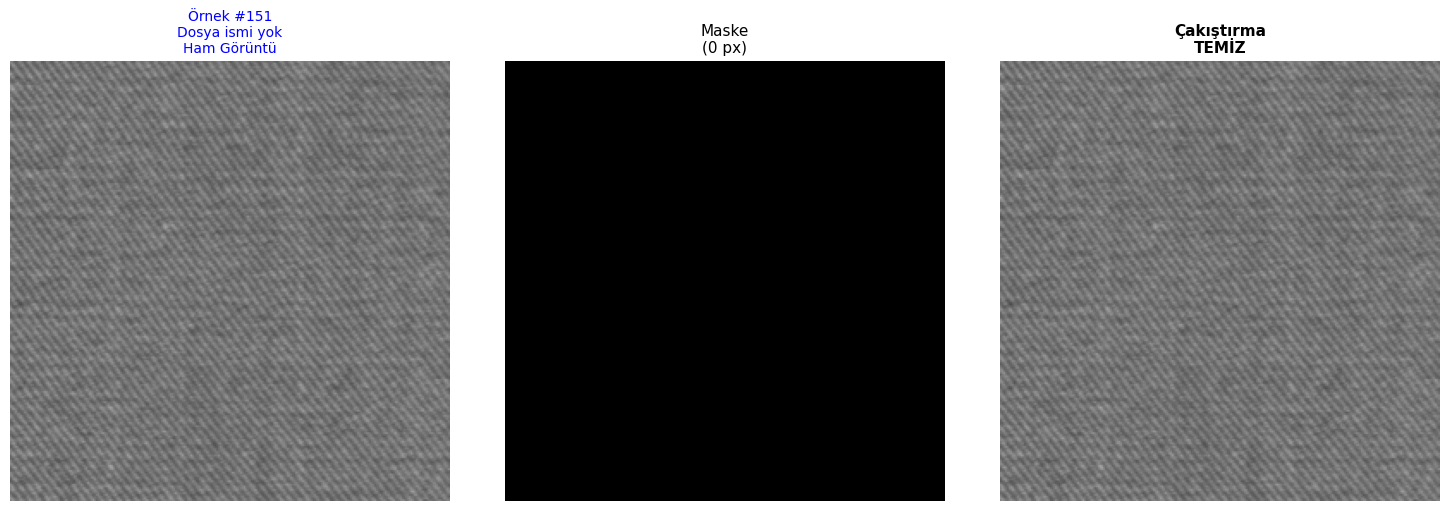

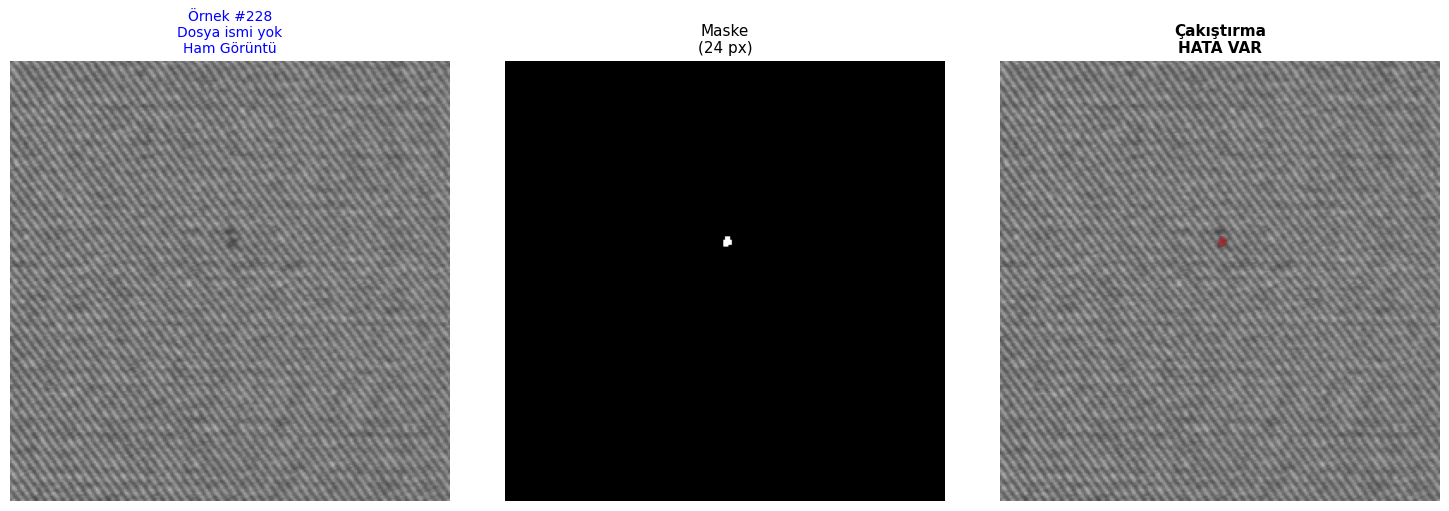

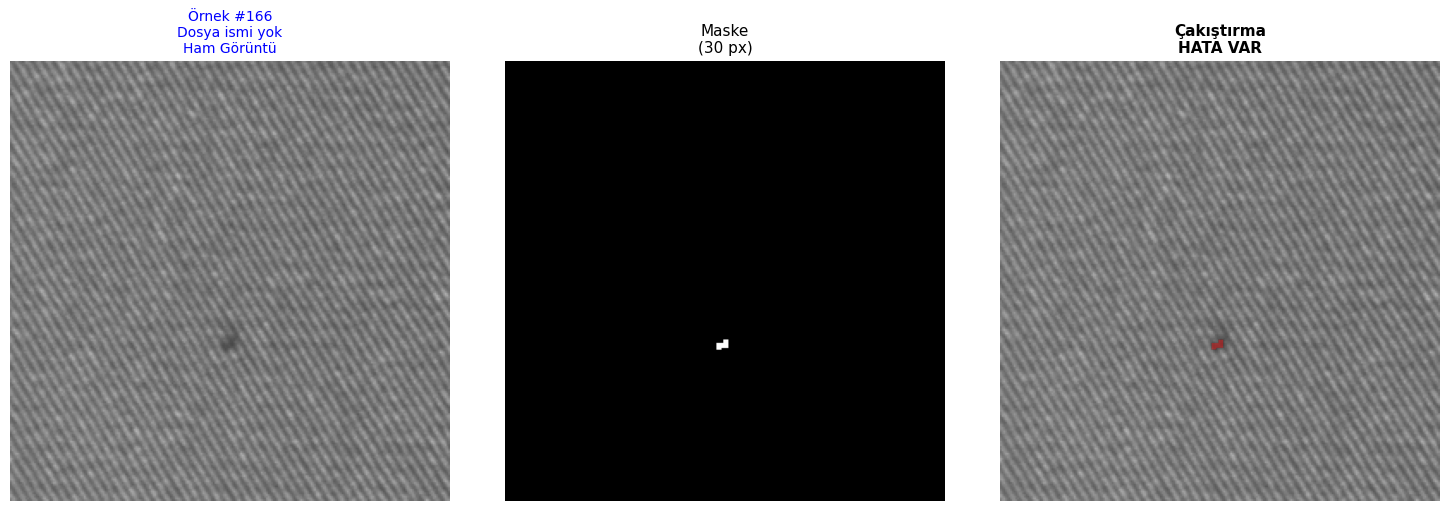

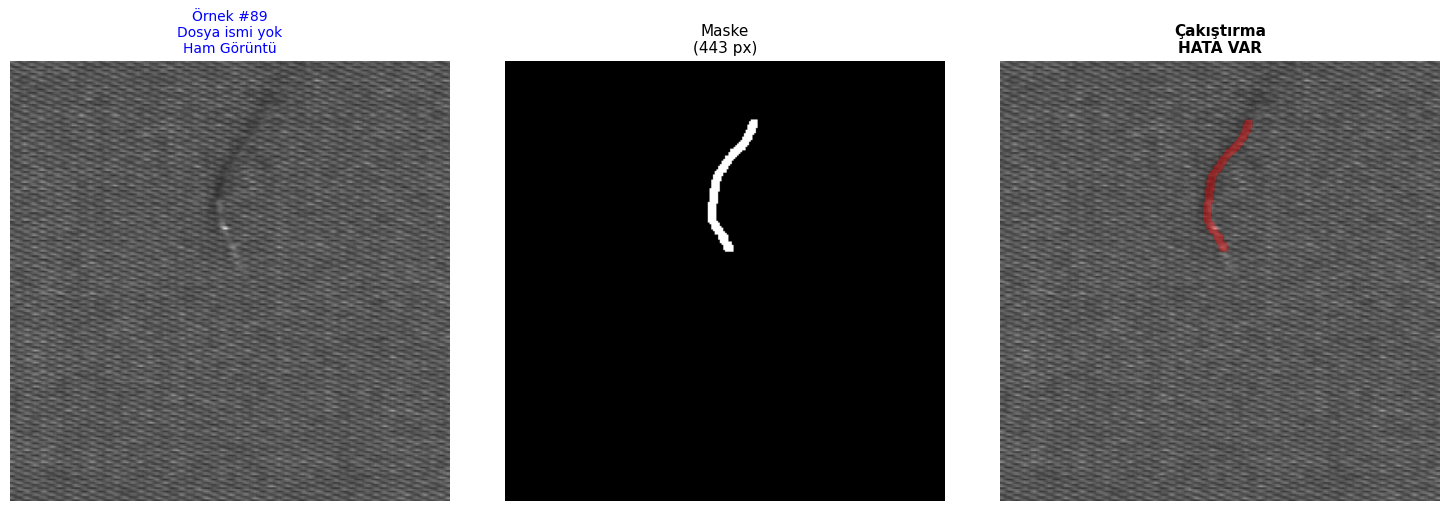

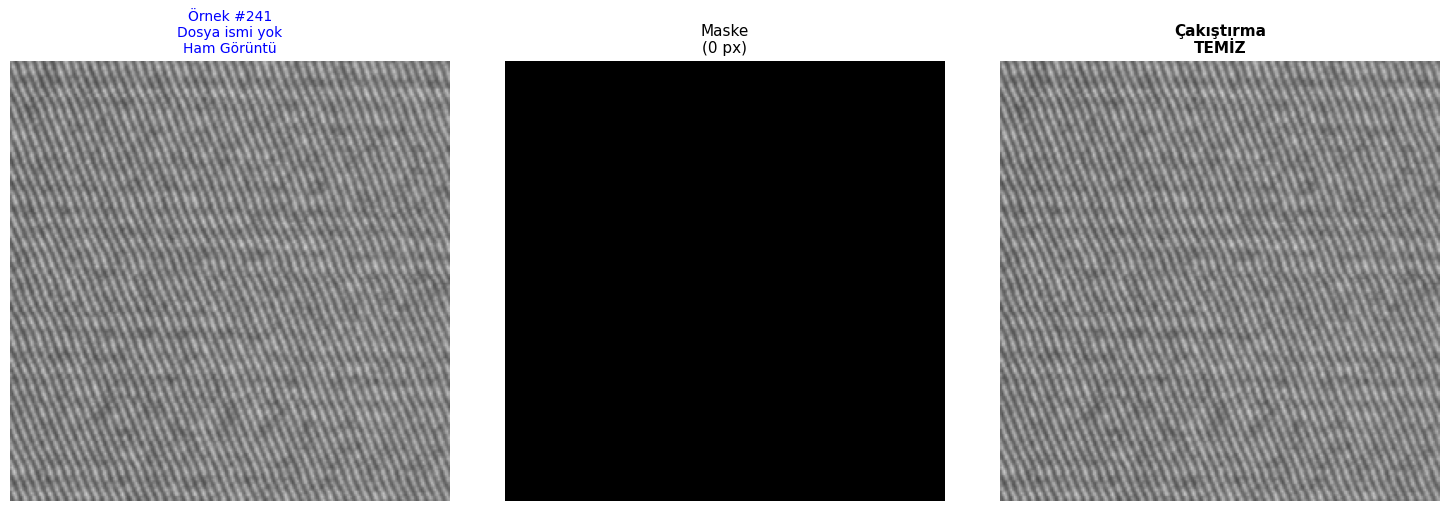

In [19]:
import matplotlib.pyplot as plt
import numpy as np

def simple_visualize(dataset, num_samples=5):
    """
    GÜNCELLENMİŞ VERSİYON:
    Dataset artık 3 değer döndürdüğü için (resim, maske, dosya_ismi)
    bu fonksiyon da ona göre güncellendi.
    """
    print(f"\n{'='*60}")
    print(f"DOĞAL GÖRÜNTÜLEME (DOSYA İSİMLİ) - {num_samples} ÖRNEK")
    print(f"{'='*60}")
    
    # Rastgele indexler seç
    if len(dataset) < num_samples:
        indices = range(len(dataset))
    else:
        indices = np.random.choice(len(dataset), num_samples, replace=False)
    
    for i, idx in enumerate(indices):
        # --- DÜZELTME BURADA ---
        # Artık 3 değer geliyor, üçünü de karşılıyoruz.
        # Eğer eski dataset sınıfı hafızadaysa ve 2 değer dönerse diye önlem alalım:
        data = dataset.get_item(idx)
        
        if len(data) == 3:
            image, mask, filename = data
        else:
            image, mask = data
            filename = "Dosya ismi yok"
        # -----------------------
        
        img_show = image[:, :, 0]
        mask_show = mask[:, :, 0]
        
        defect_pixels = np.sum(mask_show > 0)
        has_defect = defect_pixels > 0
        
        fig, axes = plt.subplots(1, 3, figsize=(15, 5))
        
        # 1. ORİJİNAL GÖRÜNTÜ
        axes[0].imshow(img_show, cmap='gray', vmin=0, vmax=1)
        # Başlığa dosya ismini de ekledik, kontrol için harika olur
        axes[0].set_title(f"Örnek #{idx}\n{filename}\nHam Görüntü", fontsize=10, color='blue')
        axes[0].axis('off')
        
        # 2. MASKE
        axes[1].imshow(mask_show, cmap='gray', vmin=0, vmax=1)
        axes[1].set_title(f"Maske\n({int(defect_pixels)} px)", fontsize=11)
        axes[1].axis('off')
        
        # 3. ÇAKIŞTIRMA
        axes[2].imshow(img_show, cmap='gray', vmin=0, vmax=1)
        if has_defect:
            overlay = np.zeros((img_show.shape[0], img_show.shape[1], 4))
            overlay[mask_show > 0] = [1, 0, 0, 0.4] 
            axes[2].imshow(overlay)
            status = "HATA VAR"
        else:
            status = "TEMİZ"
            
        axes[2].set_title(f"Çakıştırma\n{status}", fontsize=11, fontweight='bold')
        axes[2].axis('off')
        
        plt.tight_layout()
        plt.show()

# Şimdi tekrar çalıştırabilirsin
print("Validation Setinden Örnekler:")
simple_visualize(val_dataset_obj, num_samples=5)


EN ÇOK HATALI GÖRÜNEN 5 ÖRNEK (TEMİZLENMİŞ VERİ SETİNDEN):



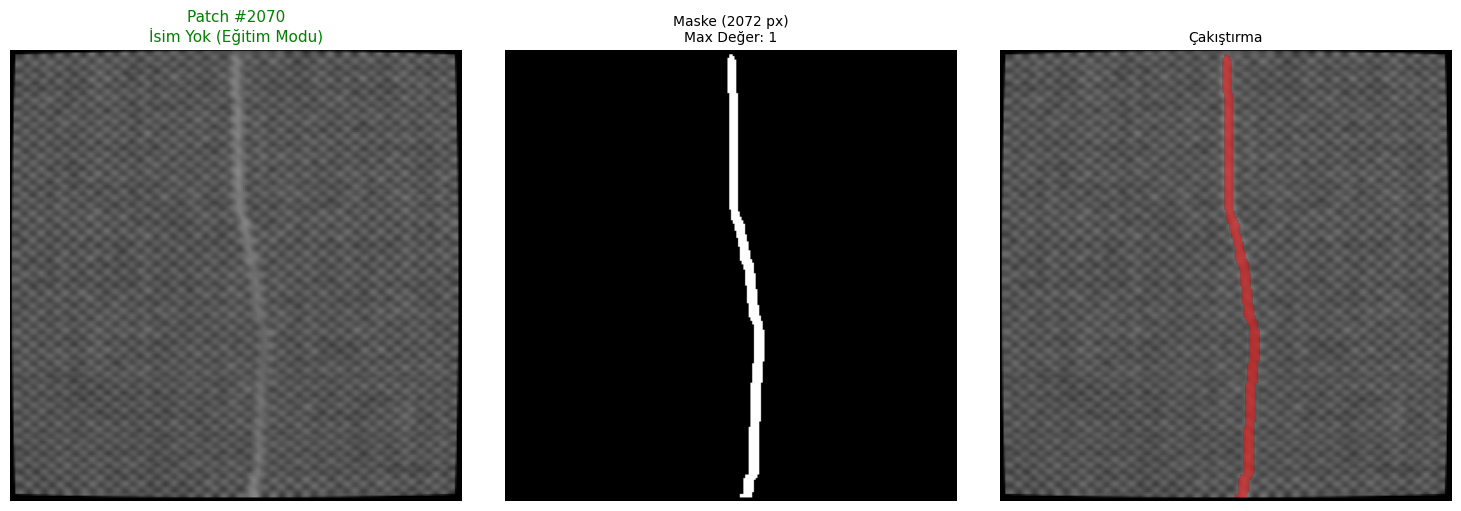

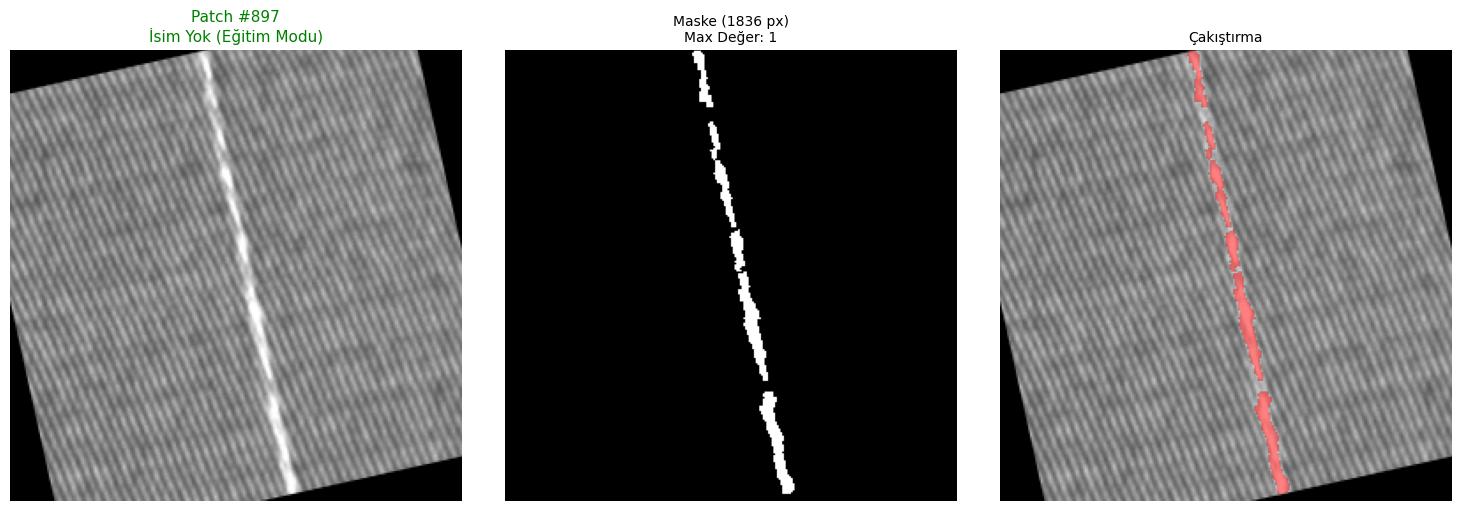

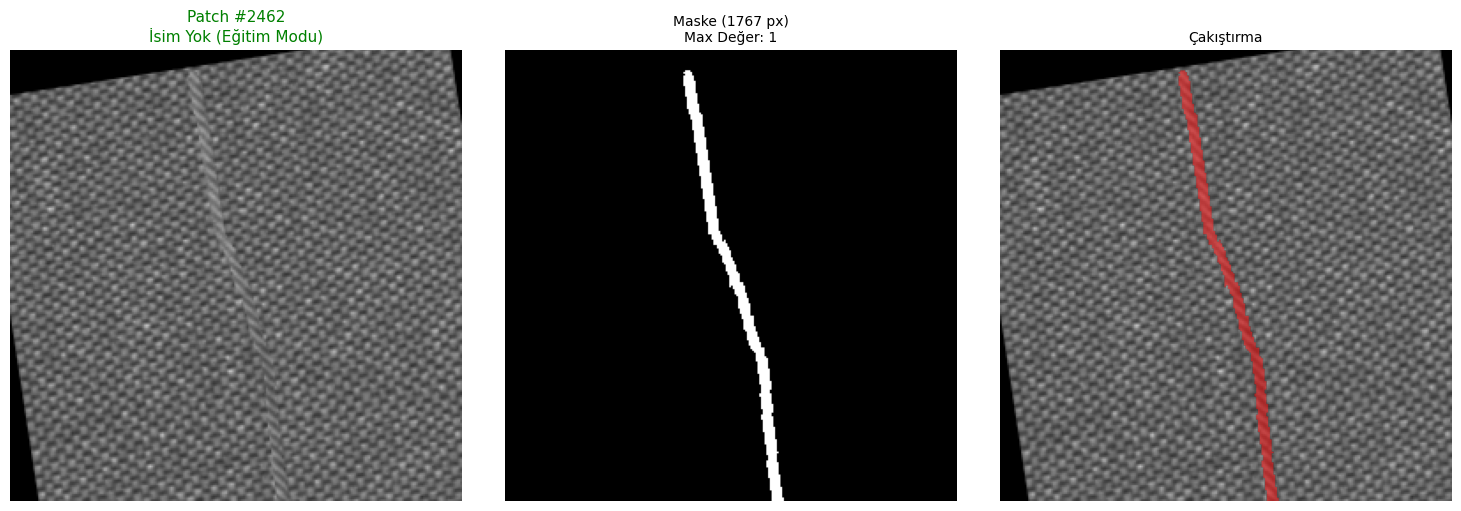

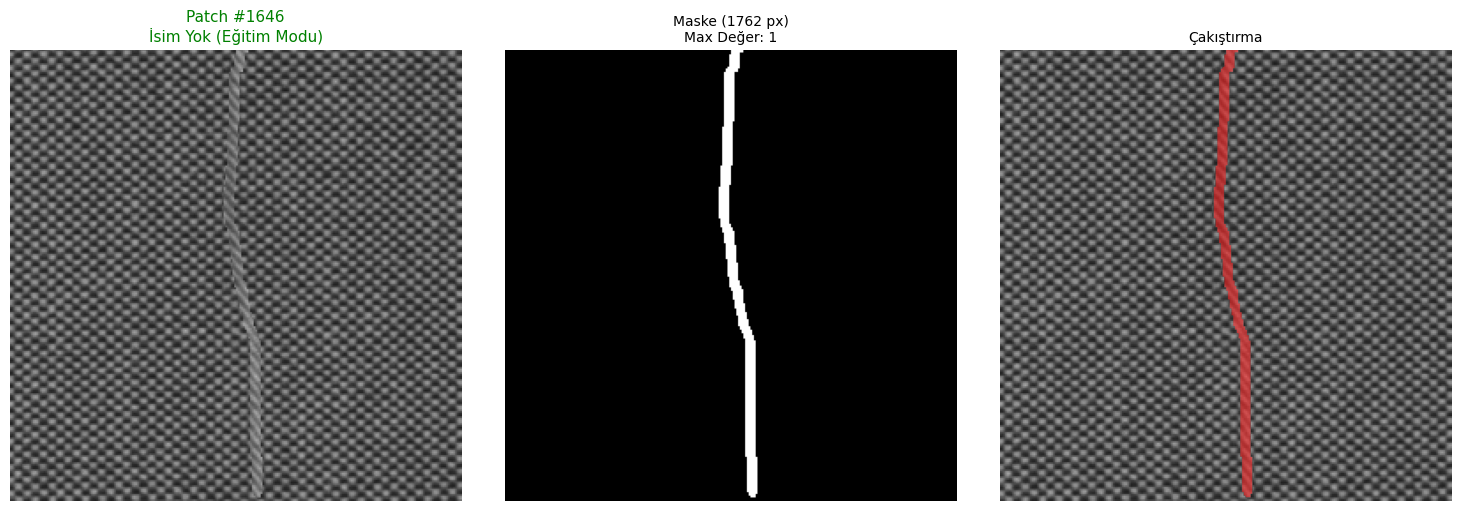

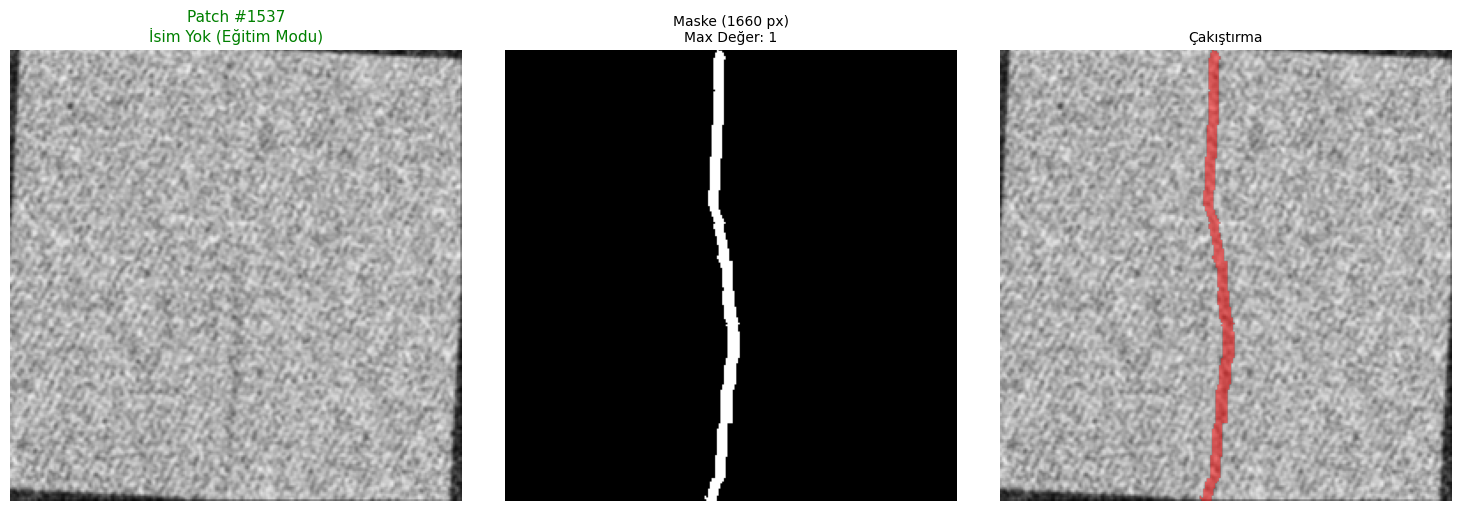

In [20]:
import matplotlib.pyplot as plt
import numpy as np

def visualize_with_filename(dataset_obj, num_samples=5):
    """
    Bu fonksiyon artık hem 2'li (Eğitim Modu) hem 3'lü (Debug Modu) 
    dönüşleri destekler. Hata vermez.
    """
    defect_indices = [i for i, label in enumerate(dataset_obj.labels) if label == 1]
    if not defect_indices: 
        print("Dataset'te hiç hata (defect) kalmamış!")
        return
    
    # En çok hatalı olanları bul
    defect_counts = []
    for idx in defect_indices:
        # --- GÜVENLİ VERİ ALMA ---
        data = dataset_obj.get_item(idx)
        if len(data) == 3:
            _, mask, _ = data
        else:
            _, mask = data
            
        count = np.sum(mask > 0)
        defect_counts.append((idx, count))
    
    defect_counts.sort(key=lambda x: x[1], reverse=True)
    
    print(f"\nEN ÇOK HATALI GÖRÜNEN {num_samples} ÖRNEK (TEMİZLENMİŞ VERİ SETİNDEN):\n")
    
    for i in range(min(num_samples, len(defect_counts))):
        idx, count = defect_counts[i]
        
        # --- TEKRAR GÜVENLİ VERİ ALMA ---
        data = dataset_obj.get_item(idx)
        if len(data) == 3:
            img, mask, filename = data
        else:
            img, mask = data
            filename = "İsim Yok (Eğitim Modu)" # 2 değer döndüğü için isim elimizde yok
        
        # Grafik
        fig, axes = plt.subplots(1, 3, figsize=(15, 5))
        
        # Resim
        axes[0].imshow(img[:,:,0], cmap='gray', vmin=0, vmax=1)
        axes[0].set_title(f"Patch #{idx}\n{filename}", fontsize=11, color='green')
        axes[0].axis('off')
        
        # Maske
        axes[1].imshow(mask[:,:,0], cmap='gray', vmin=0, vmax=1)
        axes[1].set_title(f"Maske ({count:.0f} px)\nMax Değer: {mask.max():.0f}", fontsize=10)
        axes[1].axis('off')
        
        # Çakıştırma
        axes[2].imshow(img[:,:,0], cmap='gray', vmin=0, vmax=1)
        overlay = np.zeros((256, 256, 4))
        overlay[mask[:,:,0] > 0] = [1, 0, 0, 0.5]
        axes[2].imshow(overlay)
        axes[2].set_title("Çakıştırma", fontsize=10)
        axes[2].axis('off')
        
        plt.tight_layout()
        plt.show()

# Kodu Çalıştır
visualize_with_filename(train_dataset_obj, num_samples=5)

In [21]:
def predict_with_tta(model, image_np):
    """
    Averages predictions over 8 geometric augmentations
    (original + 3 rotations + 4 flips) to boost val Dice.
    image_np shape: (H, W, 1), float32 in [0,1]
    """
    augmented_inputs = [
        image_np,
        np.rot90(image_np, 1),
        np.rot90(image_np, 2),
        np.rot90(image_np, 3),
        np.fliplr(image_np),
        np.flipud(image_np),
        np.fliplr(np.rot90(image_np, 1)),
        np.flipud(np.rot90(image_np, 1)),
    ]

    preds = []
    for aug in augmented_inputs:
        inp  = np.expand_dims(aug, axis=0)
        pred = model.predict(inp, verbose=0)[0]
        preds.append(pred)

    preds[1] = np.rot90(preds[1], -1)
    preds[2] = np.rot90(preds[2], -2)
    preds[3] = np.rot90(preds[3], -3)
    preds[4] = np.fliplr(preds[4])
    preds[5] = np.flipud(preds[5])
    preds[6] = np.rot90(np.fliplr(preds[6]), -1)
    preds[7] = np.flipud(np.rot90(preds[7], -1))

    return np.mean(preds, axis=0)


def multi_threshold_evaluation_tta(model, dataset_obj,
                                    thresholds=np.arange(0.10, 0.75, 0.05)):
    """Same as multi_threshold_evaluation but uses TTA."""
    print("="*70)
    print("MULTI-THRESHOLD EVALUATION WITH TTA")
    print("="*70)
    print("Generating TTA predictions (slower — be patient)...")

    all_preds, all_masks = [], []
    for i in range(len(dataset_obj)):
        img, mask = dataset_obj.get_item(i)
        pred = predict_with_tta(model, img)
        all_preds.append(pred[:, :, 0].flatten())
        all_masks.append(mask[:, :, 0].flatten())

    all_preds = np.concatenate(all_preds)
    all_masks  = np.concatenate(all_masks)

    print(f"\n{'Threshold':<12}{'Dice':<10}{'IoU':<10}{'Recall':<10}{'Precision':<10}{'F1':<10}")
    print("-"*60)

    results = []
    for t in thresholds:
        pred_bin  = (all_preds >= t).astype(np.float32)
        tp = np.sum(all_masks * pred_bin)
        fp = np.sum((1 - all_masks) * pred_bin)
        fn = np.sum(all_masks * (1 - pred_bin))
        dice      = (2 * tp) / (2 * tp + fp + fn + 1e-7)
        iou       = tp / (tp + fp + fn + 1e-7)
        recall    = tp / (tp + fn + 1e-7)
        precision = tp / (tp + fp + 1e-7)
        f1        = 2 * (precision * recall) / (precision + recall + 1e-7)
        print(f"{t:<12.2f}{dice:<10.4f}{iou:<10.4f}{recall:<10.4f}{precision:<10.4f}{f1:<10.4f}")
        results.append((t, dict(dice=dice, iou=iou, recall=recall,
                                precision=precision, f1=f1)))

    best_thresh, best_metrics = max(results, key=lambda x: x[1]['f1'])
    print(f"\nBEST THRESHOLD (TTA): {best_thresh:.2f}")
    for k, v in best_metrics.items():
        print(f"  {k.capitalize()}: {v:.4f}")

    return best_thresh, best_metrics


In [22]:
import os
import cv2
import matplotlib.pyplot as plt
import numpy as np
import shutil

def save_prediction_results(model, dataset_obj, output_folder="Model_Sonuclari", num_samples=20, threshold=0.5):
    """
    Model tahminlerini görselleştirir ve klasöre kaydeder.
    """
    # 1. Klasör Yapısını Oluştur
    plot_dir = os.path.join(output_folder, "karsilastirma_tablolari")
    mask_dir = os.path.join(output_folder, "saf_tahmin_maskeleri")
    
    os.makedirs(plot_dir, exist_ok=True)
    os.makedirs(mask_dir, exist_ok=True)
    
    print(f"💾 Kayıt İşlemi Başladı... Hedef Klasör: {output_folder}")
    
    count_saved = 0
    
    # 2. Döngü
    for i in range(min(num_samples, len(dataset_obj))):
        # Veriyi al
        img, true_mask = dataset_obj.get_item(i)
        
        # Model Tahmini
        input_img = np.expand_dims(img, axis=0)
        pred_prob = model.predict(input_img, verbose=0)[0] # Olasılık haritası (0.0 - 1.0)
        
        # Binary Maske (Eşiklenmiş - 0 veya 1)
        pred_binary = (pred_prob > threshold).astype(np.float32)
        
        # --- A) KARŞILAŞTIRMA GRAFİĞİNİ KAYDET ---
        fig, axes = plt.subplots(1, 3, figsize=(15, 5))
        
        # Orijinal
        axes[0].imshow(img[:,:,0], cmap='gray')
        axes[0].set_title(f"Örnek #{i} - Orijinal")
        axes[0].axis('off')
        
        # Gerçek Maske
        axes[1].imshow(true_mask[:,:,0], cmap='gray', vmin=0, vmax=1)
        axes[1].set_title("Gerçek Maske (Ground Truth)")
        axes[1].axis('off')
        
        # Model Tahmini (Renkli Olasılık)
        # Olasılıkları görelim ki modelin ne kadar emin olduğunu anlayalım
        axes[2].imshow(pred_prob[:,:,0], cmap='inferno', vmin=0, vmax=1) 
        axes[2].set_title(f"Model Tahmini\n(Max Güven: {pred_prob.max():.2f})")
        axes[2].axis('off')
        
        # Grafiği Kaydet
        plot_path = os.path.join(plot_dir, f"result_{i:03d}_plot.png")
        plt.savefig(plot_path, bbox_inches='tight')
        plt.close(fig) # Hafızayı şişirmemek için kapat
        
        # --- B) SAF MASKEYİ KAYDET (PNG) ---
        # 0-1 arası değeri 0-255 yapıp kaydediyoruz
        mask_path = os.path.join(mask_dir, f"result_{i:03d}_mask.png")
        cv2.imwrite(mask_path, (pred_binary * 255).astype(np.uint8))
        
        count_saved += 1
        if (i+1) % 10 == 0:
            print(f"   -> {i+1} adet görsel işlendi...")

    print(f"\n✅ İŞLEM TAMAM! Toplam {count_saved} görsel '{output_folder}' içine kaydedildi.")
    
    # 3. Klasörü İndirmek İçin Zip Yap (Kaggle/Colab için çok yararlı)
    shutil.make_archive(output_folder, 'zip', output_folder)
    print(f"📦 '{output_folder}.zip' dosyası oluşturuldu. İndirebilirsiniz!")



In [23]:
import pandas as pd
import matplotlib.pyplot as plt
import os

def save_training_metrics(history, model_name="Model", output_folder="Model_Metrikleri"):
    """
    Eğitim geçmişini (history) CSV olarak kaydeder ve grafiklerini çizer.
    """
    # 1. Klasörü Oluştur
    os.makedirs(output_folder, exist_ok=True)
    print(f"📊 Metrik Kaydı Başladı... Hedef: {output_folder}")
    
    # 2. Verileri DataFrame'e Çevir ve Kaydet (Excel/CSV)
    # history.history bir sözlüktür, bunu tabloya çeviriyoruz
    df = pd.DataFrame(history.history)
    
    # En iyi epoch'u bul (Dice skoruna göre)
    if 'val_dice_coef' in df.columns:
        best_epoch = df['val_dice_coef'].idxmax()
        print(f"   🌟 En İyi Epoch: {best_epoch + 1} (Val Dice: {df.loc[best_epoch, 'val_dice_coef']:.4f})")
    
    # CSV Dosyası Olarak Kaydet
    csv_path = os.path.join(output_folder, f"{model_name}_training_log.csv")
    df.to_csv(csv_path, index_label="Epoch")
    print(f"   💾 Tablo kaydedildi: {csv_path}")
    
    # 3. Grafikleri Çiz ve Kaydet
    metrics_to_plot = [
        ('loss', 'val_loss', 'Loss (Kayıp) Grafiği', 'min'),
        ('dice_coef', 'val_dice_coef', 'Dice Skoru (Başarı)', 'max'),
        ('accuracy', 'val_accuracy', 'Accuracy (Doğruluk)', 'max')
    ]
    
    plt.figure(figsize=(18, 5))
    
    for i, (train_metric, val_metric, title, mode) in enumerate(metrics_to_plot):
        if train_metric not in df.columns: continue
        
        plt.subplot(1, 3, i+1)
        plt.plot(df[train_metric], label=f'Eğitim {train_metric}', linewidth=2)
        plt.plot(df[val_metric], label=f'Doğrulama {val_metric}', linewidth=2, linestyle='--')
        
        # En iyi noktayı işaretle
        if mode == 'min':
            best_idx = df[val_metric].idxmin()
            best_val = df[val_metric].min()
            color = 'red'
        else:
            best_idx = df[val_metric].idxmax()
            best_val = df[val_metric].max()
            color = 'green'
            
        plt.scatter(best_idx, best_val, c=color, s=100, zorder=5, label=f'En İyi: {best_val:.4f}')
        
        plt.title(f"{model_name} - {title}")
        plt.xlabel("Epoch")
        plt.ylabel("Değer")
        plt.legend()
        plt.grid(True, alpha=0.3)
    
    # Grafiği Kaydet
    plot_path = os.path.join(output_folder, f"{model_name}_metrics_plot.png")
    plt.savefig(plot_path, bbox_inches='tight')
    plt.close()
    print(f"   📈 Grafik kaydedildi: {plot_path}")
    print("-" * 50)


In [24]:
# Custom metrics for Keras
def dice_coef(y_true, y_pred, smooth=1e-6):
    y_true_f = tf.reshape(y_true, [-1])
    y_pred_f = tf.reshape(y_pred, [-1])
    intersection = tf.reduce_sum(y_true_f * y_pred_f)
    return (2. * intersection + smooth) / (tf.reduce_sum(y_true_f) + tf.reduce_sum(y_pred_f) + smooth)

def dice_loss(y_true, y_pred):
    return 1 - dice_coef(y_true, y_pred)

def bce_dice_loss(y_true, y_pred):
    # Hem binary cross entropy (genel dağılım) 
    # Hem de dice loss (kesişim başarısı) beraber kullanılır
    bce = tf.keras.losses.binary_crossentropy(y_true, y_pred)
    dice = dice_loss(y_true, y_pred)
    return bce + dice
    
def iou_coef(y_true, y_pred, smooth=1e-6):
    y_true_f = tf.reshape(y_true, [-1])
    y_pred_f = tf.reshape(y_pred, [-1])
    intersection = tf.reduce_sum(y_true_f * y_pred_f)
    union = tf.reduce_sum(y_true_f) + tf.reduce_sum(y_pred_f) - intersection
    return (intersection + smooth) / (union + smooth)

def recall_m(y_true, y_pred):
    y_true_f = tf.reshape(y_true, [-1])
    y_pred_f = tf.reshape(y_pred, [-1])
    true_positives = tf.reduce_sum(y_true_f * y_pred_f)
    possible_positives = tf.reduce_sum(y_true_f)
    return true_positives / (possible_positives + 1e-6)

def precision_m(y_true, y_pred):
    y_true_f = tf.reshape(y_true, [-1])
    y_pred_f = tf.reshape(y_pred, [-1])
    true_positives = tf.reduce_sum(y_true_f * y_pred_f)
    predicted_positives = tf.reduce_sum(y_pred_f)
    return true_positives / (predicted_positives + 1e-6)

def f1_m(y_true, y_pred):
    precision = precision_m(y_true, y_pred)
    recall = recall_m(y_true, y_pred)
    return 2*((precision*recall)/(precision+recall+1e-6))

In [25]:
# Define callbacks for training
callbacks_list = [
    callbacks.ModelCheckpoint(
        'best_model.h5',
        monitor='val_loss',
        save_best_only=True,
        mode='min',
        verbose=1
    ),
    callbacks.EarlyStopping(
        monitor='val_loss',
        patience=30,
        restore_best_weights=True,
        verbose=1
    ),
    callbacks.ReduceLROnPlateau(
        monitor='val_loss',
        factor=0.5,
        patience=10,
        min_lr=1e-7,
        verbose=1
    ),
    callbacks.CSVLogger('training_log.csv'),
]


In [26]:
# Prepare image and mask file lists using only valid .png mask files
train_image_dir = os.path.join(Config.DATA_PATH, "train", "images")
train_mask_dir  = os.path.join(Config.DATA_PATH, "train", "masks")
val_image_dir   = os.path.join(Config.DATA_PATH, "val", "images")
val_mask_dir    = os.path.join(Config.DATA_PATH, "val", "masks")

# Filter valid train pairs
valid_train_mask_files = [f for f in os.listdir(train_mask_dir) if f.endswith('.png')]
train_image_mask_pairs = []
for mask_file in valid_train_mask_files:
    image_file = mask_file.replace('_mask.png', '.png')
    image_path = os.path.join(train_image_dir, image_file)
    mask_path  = os.path.join(train_mask_dir, mask_file)
    if os.path.exists(image_path):
        train_image_mask_pairs.append((image_path, mask_path))

# Filter valid val pairs
valid_val_mask_files = [f for f in os.listdir(val_mask_dir) if f.endswith('.png')]
val_image_mask_pairs = []
for mask_file in valid_val_mask_files:
    image_file = mask_file.replace('_mask.png', '.png')
    image_path = os.path.join(val_image_dir, image_file)
    mask_path  = os.path.join(val_mask_dir, mask_file)
    if os.path.exists(image_path):
        val_image_mask_pairs.append((image_path, mask_path))

# Split into separate lists
train_images = [pair[0] for pair in train_image_mask_pairs]
train_masks  = [pair[1] for pair in train_image_mask_pairs]
val_images   = [pair[0] for pair in val_image_mask_pairs]
val_masks    = [pair[1] for pair in val_image_mask_pairs]

# Create dataset objects (copy-paste injection happens in the NEXT cell)
train_dataset_obj = AITexDataset(train_images, train_masks, Config, mode='train', ignore_list=BLACKLIST)
val_dataset_obj   = AITexDataset(val_images,   val_masks,   Config, mode='val',   ignore_list=BLACKLIST)

print("Training patches:", len(train_dataset_obj.patches))
print("Validation patches:", len(val_dataset_obj.patches))


EXTRACTING PATCHES (TRAIN) - FILTERING ACTIVE
Blacklist Size: 15 files
BLOCKED: '0103_010_03.png' (Matched blacklist item: '0103_010_03.png')

Blocked 12 corrupt files/copies.
EXTRACTING PATCHES (VAL) - FILTERING ACTIVE
Blacklist Size: 15 files

Blocked 3 corrupt files/copies.
Training patches: 1120
Validation patches: 272


In [27]:
# Inject synthetic defect patches via copy-paste BEFORE building tf.data pipeline
extra_patches = defect_copy_paste(train_dataset_obj, multiplier=3)
train_dataset_obj.patches.extend(extra_patches)
train_dataset_obj.labels.extend([1] * len(extra_patches))
print(f"Training set after copy-paste: {len(train_dataset_obj.patches)} patches")


✅ Generated 1878 synthetic defect patches via copy-paste.
Training set after copy-paste: 2998 patches


In [28]:
# Build tf.data pipeline AFTER copy-paste injection
train_dataset = create_balanced_tf_dataset(train_dataset_obj, Config.BATCH_SIZE, mode='train')
val_dataset   = create_balanced_tf_dataset(val_dataset_obj,   Config.BATCH_SIZE, mode='val')
print("tf.data pipelines ready.")



CREATING BALANCED TRAINING DATASET
Original distribution:
  Defect: 2504
  Normal: 494
  Ratio: 1:0.2
  Total training samples: 2998

tf.data pipelines ready.


I0000 00:00:1781292200.704370      22 gpu_device.cc:2019] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13757 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1781292200.710723      22 gpu_device.cc:2019] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13757 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


In [29]:
# Veri Kontrolü
sample_img, sample_mask = train_dataset_obj.get_item(0)
print(f"Maske Min Değeri: {sample_mask.min()}")
print(f"Maske Max Değeri: {sample_mask.max()}")

if sample_mask.max() > 1.0:
    print("HATA: Maske hala 255 (veya büyük) değer içeriyor!")
else:
    print("BAŞARILI: Maske 0-1 aralığında.")

Maske Min Değeri: 0.0
Maske Max Değeri: 1.0
BAŞARILI: Maske 0-1 aralığında.



Training Attention U-Net model...
Epoch 1/200


I0000 00:00:1781292228.649129      77 service.cc:152] XLA service 0x7f59541423a0 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1781292228.649191      77 service.cc:160]   StreamExecutor device (0): Tesla T4, Compute Capability 7.5
I0000 00:00:1781292228.649196      77 service.cc:160]   StreamExecutor device (1): Tesla T4, Compute Capability 7.5
I0000 00:00:1781292232.511906      77 cuda_dnn.cc:529] Loaded cuDNN version 91002
2026-06-12 19:24:02.188355: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-06-12 19:24:02.477295: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-06-12 19:24:03.509452: E external/local_xl

    187/Unknown 109s 219ms/step - accuracy: 0.9691 - dice_coef: 0.0076 - loss: 1.3151

2026-06-12 19:25:21.863311: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-06-12 19:25:22.154710: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-06-12 19:25:22.973700: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-06-12 19:25:23.281494: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-06-12 19:25:23.653229: E external/local_xla/xla/stream_

    188/Unknown 147s 422ms/step - accuracy: 0.9692 - dice_coef: 0.0076 - loss: 1.3148
Epoch 1: val_loss improved from inf to 1.17988, saving model to best_model.h5


...

188/188 ━━━━━━━━━━━━━━━━━━━━ 52s 242ms/step - accuracy: 0.9978 - dice_coef: 0.6478 - loss: 0.3679 - val_accuracy: 0.9975 - val_dice_coef: 0.3958 - val_loss: 0.6214 - learning_rate: 1.0000e-04
Epoch 40/200
188/188 ━━━━━━━━━━━━━━━━━━━━ 0s 234ms/step - accuracy: 0.9979 - dice_coef: 0.6563 - loss: 0.3586
Epoch 40: val_loss did not improve from 0.62143
188/188 ━━━━━━━━━━━━━━━━━━━━ 53s 240ms/step - accuracy: 0.9979 - dice_coef: 0.6562 - loss: 0.3587 - val_accuracy: 0.9971 - val_dice_coef: 0.3737 - val_loss: 0.6451 - learning_rate: 1.0000e-04
Epoch 41/200
188/188 ━━━━━━━━━━━━━━━━━━━━ 0s 232ms/step - accuracy: 0.9977 - dice_coef: 0.6462 - loss: 0.3698
Epoch 41: val_loss did not improve from 0.62143
188/188 ━━━━━━━━━━━━━━━━━━━━ 53s 239ms/step - accuracy: 0.9977 - dice_coef: 0.6461 - loss: 0.3699 - val_accuracy: 0.9974 - val_dice_coef: 0.3835 - val_loss: 0.6349 - learning_rate: 1.0000e-04
Epoch 42/200
188/188 ━━━━━━━━━━━━━━━━━━━━ 0s 232ms/step - accuracy: 0.9977 - dice_coef: 0.6350 - loss: 0.381

188/188 ━━━━━━━━━━━━━━━━━━━━ 51s 239ms/step - accuracy: 0.9978 - dice_coef: 0.6443 - loss: 0.3717 - val_accuracy: 0.9974 - val_dice_coef: 0.4027 - val_loss: 0.6150 - learning_rate: 1.0000e-04
Epoch 48/200
188/188 ━━━━━━━━━━━━━━━━━━━━ 0s 231ms/step - accuracy: 0.9979 - dice_coef: 0.6651 - loss: 0.3504
Epoch 48: val_loss improved from 0.61496 to 0.61354, saving model to best_model.h5


188/188 ━━━━━━━━━━━━━━━━━━━━ 51s 240ms/step - accuracy: 0.9979 - dice_coef: 0.6651 - loss: 0.3504 - val_accuracy: 0.9977 - val_dice_coef: 0.4035 - val_loss: 0.6135 - learning_rate: 1.0000e-04
Epoch 49/200
188/188 ━━━━━━━━━━━━━━━━━━━━ 0s 231ms/step - accuracy: 0.9978 - dice_coef: 0.6765 - loss: 0.3391
Epoch 49: val_loss improved from 0.61354 to 0.60955, saving model to best_model.h5


188/188 ━━━━━━━━━━━━━━━━━━━━ 51s 240ms/step - accuracy: 0.9978 - dice_coef: 0.6764 - loss: 0.3392 - val_accuracy: 0.9976 - val_dice_coef: 0.4078 - val_loss: 0.6096 - learning_rate: 1.0000e-04
Epoch 50/200
188/188 ━━━━━━━━━━━━━━━━━━━━ 0s 231ms/step - accuracy: 0.9978 - dice_coef: 0.6483 - loss: 0.3684
Epoch 50: val_loss did not improve from 0.60955
188/188 ━━━━━━━━━━━━━━━━━━━━ 50s 238ms/step - accuracy: 0.9978 - dice_coef: 0.6484 - loss: 0.3683 - val_accuracy: 0.9975 - val_dice_coef: 0.4000 - val_loss: 0.6176 - learning_rate: 1.0000e-04
Epoch 51/200
188/188 ━━━━━━━━━━━━━━━━━━━━ 0s 232ms/step - accuracy: 0.9980 - dice_coef: 0.6709 - loss: 0.3437
Epoch 51: val_loss improved from 0.60955 to 0.57718, saving model to best_model.h5


188/188 ━━━━━━━━━━━━━━━━━━━━ 51s 240ms/step - accuracy: 0.9980 - dice_coef: 0.6709 - loss: 0.3437 - val_accuracy: 0.9977 - val_dice_coef: 0.4387 - val_loss: 0.5772 - learning_rate: 1.0000e-04
Epoch 52/200
188/188 ━━━━━━━━━━━━━━━━━━━━ 0s 231ms/step - accuracy: 0.9979 - dice_coef: 0.6870 - loss: 0.3277
Epoch 52: val_loss did not improve from 0.57718
188/188 ━━━━━━━━━━━━━━━━━━━━ 50s 238ms/step - accuracy: 0.9979 - dice_coef: 0.6870 - loss: 0.3277 - val_accuracy: 0.9975 - val_dice_coef: 0.4201 - val_loss: 0.5964 - learning_rate: 1.0000e-04
Epoch 53/200
188/188 ━━━━━━━━━━━━━━━━━━━━ 0s 231ms/step - accuracy: 0.9981 - dice_coef: 0.6909 - loss: 0.3233
Epoch 53: val_loss did not improve from 0.57718
188/188 ━━━━━━━━━━━━━━━━━━━━ 50s 238ms/step - accuracy: 0.9981 - dice_coef: 0.6909 - loss: 0.3234 - val_accuracy: 0.9977 - val_dice_coef: 0.4335 - val_loss: 0.5833 - learning_rate: 1.0000e-04
Epoch 54/200
188/188 ━━━━━━━━━━━━━━━━━━━━ 0s 231ms/step - accuracy: 0.9978 - dice_coef: 0.6594 - loss: 0.357

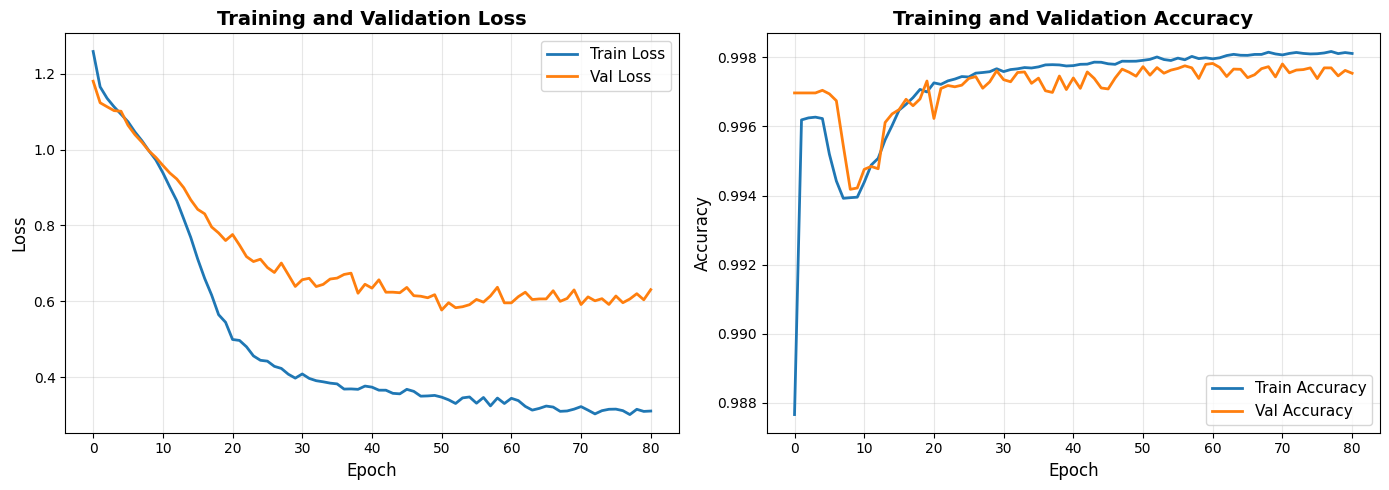


Plotting HRNet training history...


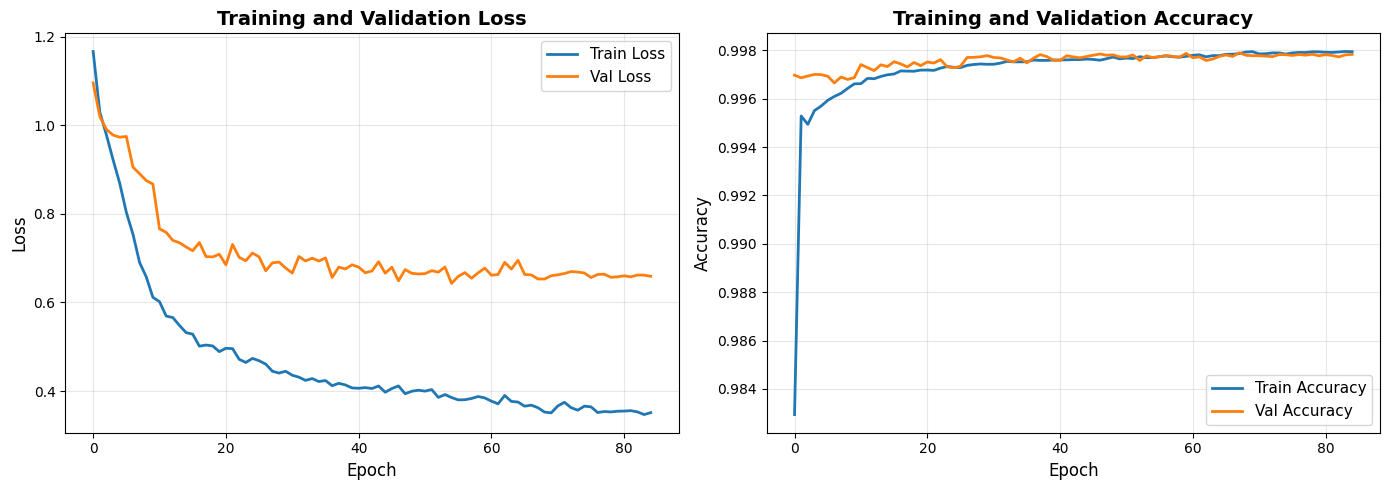


Evaluating Attention U-Net model...

MULTI-THRESHOLD EVALUATION
Generating predictions...

Threshold   Dice      IoU       Recall    Precision F1        
----------------------------------------------------------------------
0.10        0.6214    0.4507    0.6430    0.6011    0.6214    
0.20        0.6207    0.4500    0.6307    0.6111    0.6207    
0.30        0.6207    0.4500    0.6230    0.6184    0.6207    
0.40        0.6198    0.4491    0.6159    0.6238    0.6198    
0.50        0.6197    0.4489    0.6102    0.6294    0.6197    
0.60        0.6194    0.4487    0.6044    0.6352    0.6194    
0.70        0.6185    0.4477    0.5974    0.6410    0.6185    

BEST THRESHOLD: 0.10
  Dice: 0.6214
  IoU: 0.4507
  Recall: 0.6430
  Precision: 0.6011
  F1: 0.6214



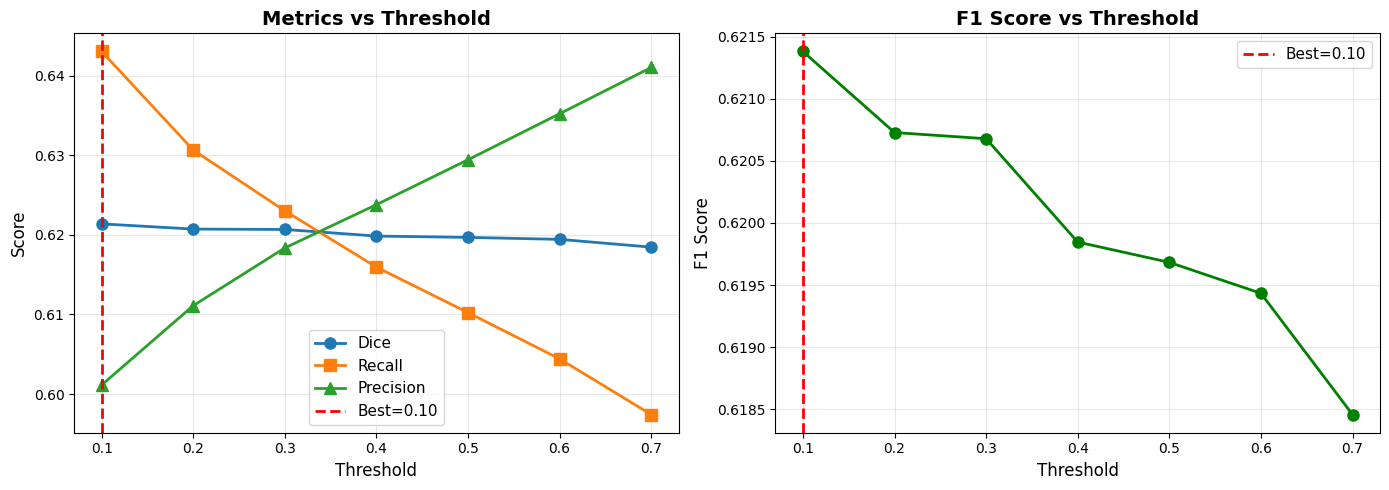


Evaluating HRNet model...

MULTI-THRESHOLD EVALUATION
Generating predictions...

Threshold   Dice      IoU       Recall    Precision F1        
----------------------------------------------------------------------
0.10        0.6024    0.4310    0.6804    0.5405    0.6024    
0.20        0.6078    0.4366    0.6484    0.5721    0.6078    
0.30        0.6104    0.4392    0.6284    0.5934    0.6104    
0.40        0.6109    0.4398    0.6113    0.6105    0.6109    
0.50        0.6093    0.4381    0.5936    0.6258    0.6093    
0.60        0.6077    0.4364    0.5778    0.6408    0.6077    
0.70        0.6044    0.4330    0.5611    0.6549    0.6044    

BEST THRESHOLD: 0.40
  Dice: 0.6109
  IoU: 0.4398
  Recall: 0.6113
  Precision: 0.6105
  F1: 0.6109



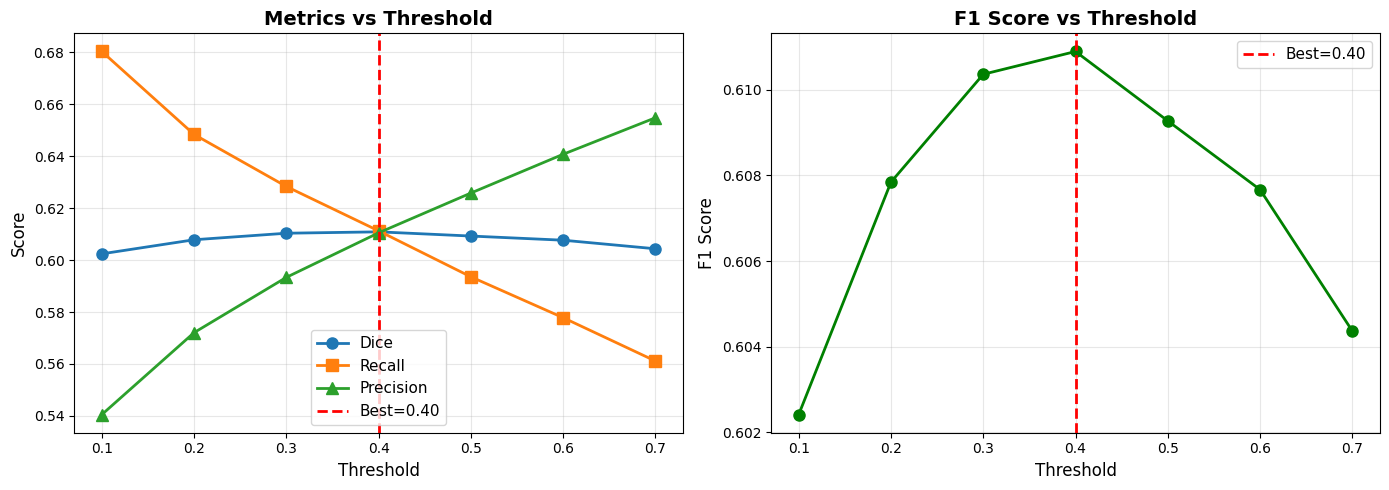


Attention U-Net Best Metrics: {'dice': np.float32(0.62137973), 'iou': np.float32(0.4507258), 'recall': np.float32(0.6430396), 'precision': np.float32(0.60113144), 'f1': np.float32(0.6213797), 'tp': 34746, 'fp': 23055, 'fn': 19288, 'tn': 17748704}
HRNet Best Metrics: {'dice': np.float32(0.6108902), 'iou': np.float32(0.439771), 'recall': np.float32(0.6112633), 'precision': np.float32(0.61051756), 'f1': np.float32(0.61089015), 'tp': 33029, 'fp': 21071, 'fn': 21005, 'tn': 17750688}


In [30]:
# Example: Training and comparing Attention U-Net and HRNet

# Build datasets
# (Assume train_dataset and val_dataset are already created as in your pipeline)

# Build models
attention_unet_model = build_attention_unet(input_shape=(256, 256, 1), filters_base=16)
hrnet_model = build_hrnet(input_shape=(Config.PATCH_SIZE, Config.PATCH_SIZE, 1), base_filters=16)

# Compile models
attention_unet_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4),
    loss=bce_dice_loss,           
    metrics=['accuracy', dice_coef] 
)

hrnet_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=Config.LEARNING_RATE),
    loss=bce_dice_loss,          
    metrics=['accuracy', dice_coef]
)


# Train Attention U-Net
print("\nTraining Attention U-Net model...")
history_attention_unet = attention_unet_model.fit(
    train_dataset,
    validation_data=val_dataset,
    epochs=Config.EPOCHS,
    callbacks=callbacks_list,
    verbose=1
)

# Train HRNet
print("\nTraining HRNet model...")
history_hrnet = hrnet_model.fit(
    train_dataset,
    validation_data=val_dataset,
    epochs=Config.EPOCHS,
    callbacks=callbacks_list,
    verbose=1
)

# Plot training histories
print("\nPlotting Attention U-Net training history...")
plot_training_history(history_attention_unet)
print("\nPlotting HRNet training history...")
plot_training_history(history_hrnet)

# Evaluate and compare
print("\nEvaluating Attention U-Net model...")
best_thresh_unet, best_metrics_unet = multi_threshold_evaluation(attention_unet_model, val_dataset)
print("\nEvaluating HRNet model...")
best_thresh_hrnet, best_metrics_hrnet = multi_threshold_evaluation(hrnet_model, val_dataset)

print("\nAttention U-Net Best Metrics:", best_metrics_unet)
print("HRNet Best Metrics:", best_metrics_hrnet)

Training Attention U-Net...
Epoch 1/200
    188/Unknown 50s 234ms/step - accuracy: 0.9979 - dice_coef: 0.6844 - loss: 0.3311
Epoch 1: val_loss did not improve from 0.57718
188/188 ━━━━━━━━━━━━━━━━━━━━ 51s 241ms/step - accuracy: 0.9979 - dice_coef: 0.6843 - loss: 0.3312 - val_accuracy: 0.9978 - val_dice_coef: 0.4306 - val_loss: 0.5857 - learning_rate: 1.2500e-05
Epoch 2/200
188/188 ━━━━━━━━━━━━━━━━━━━━ 0s 230ms/step - accuracy: 0.9980 - dice_coef: 0.6880 - loss: 0.3266
Epoch 2: val_loss did not improve from 0.57718
188/188 ━━━━━━━━━━━━━━━━━━━━ 50s 237ms/step - accuracy: 0.9980 - dice_coef: 0.6879 - loss: 0.3267 - val_accuracy: 0.9977 - val_dice_coef: 0.4310 - val_loss: 0.5854 - learning_rate: 1.2500e-05
Epoch 3/200
188/188 ━━━━━━━━━━━━━━━━━━━━ 0s 231ms/step - accuracy: 0.9980 - dice_coef: 0.6964 - loss: 0.3180
Epoch 3: val_loss did not improve from 0.57718
188/188 ━━━━━━━━━━━━━━━━━━━━ 51s 238ms/step - accuracy: 0.9980 - dice_coef: 0.6964 - loss: 0.3181 - val_accuracy: 0.9977 - val_dice_

188/188 ━━━━━━━━━━━━━━━━━━━━ 50s 239ms/step - accuracy: 0.9980 - dice_coef: 0.6983 - loss: 0.3161 - val_accuracy: 0.9978 - val_dice_coef: 0.4397 - val_loss: 0.5766 - learning_rate: 1.2500e-05
Epoch 5/200
188/188 ━━━━━━━━━━━━━━━━━━━━ 0s 231ms/step - accuracy: 0.9980 - dice_coef: 0.6742 - loss: 0.3411
Epoch 5: val_loss did not improve from 0.57660
188/188 ━━━━━━━━━━━━━━━━━━━━ 50s 237ms/step - accuracy: 0.9980 - dice_coef: 0.6743 - loss: 0.3411 - val_accuracy: 0.9977 - val_dice_coef: 0.4338 - val_loss: 0.5825 - learning_rate: 1.2500e-05
Epoch 6/200
188/188 ━━━━━━━━━━━━━━━━━━━━ 0s 231ms/step - accuracy: 0.9980 - dice_coef: 0.6951 - loss: 0.3193
Epoch 6: val_loss did not improve from 0.57660
188/188 ━━━━━━━━━━━━━━━━━━━━ 50s 237ms/step - accuracy: 0.9980 - dice_coef: 0.6950 - loss: 0.3194 - val_accuracy: 0.9977 - val_dice_coef: 0.4296 - val_loss: 0.5870 - learning_rate: 1.2500e-05
Epoch 7/200
188/188 ━━━━━━━━━━━━━━━━━━━━ 0s 231ms/step - accuracy: 0.9980 - dice_coef: 0.6866 - loss: 0.3281
Epo

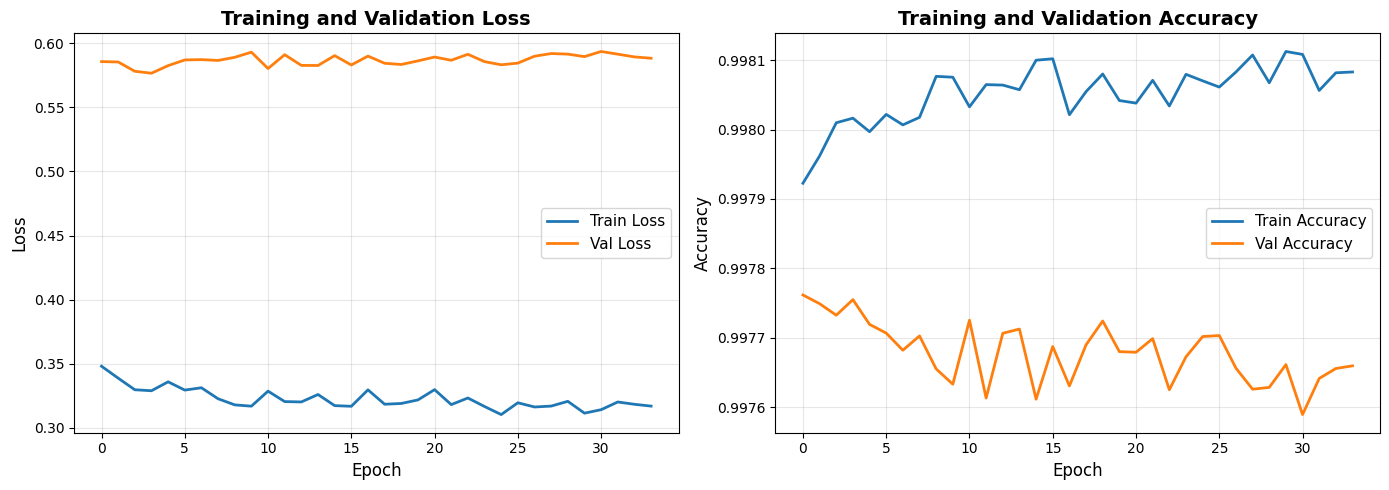

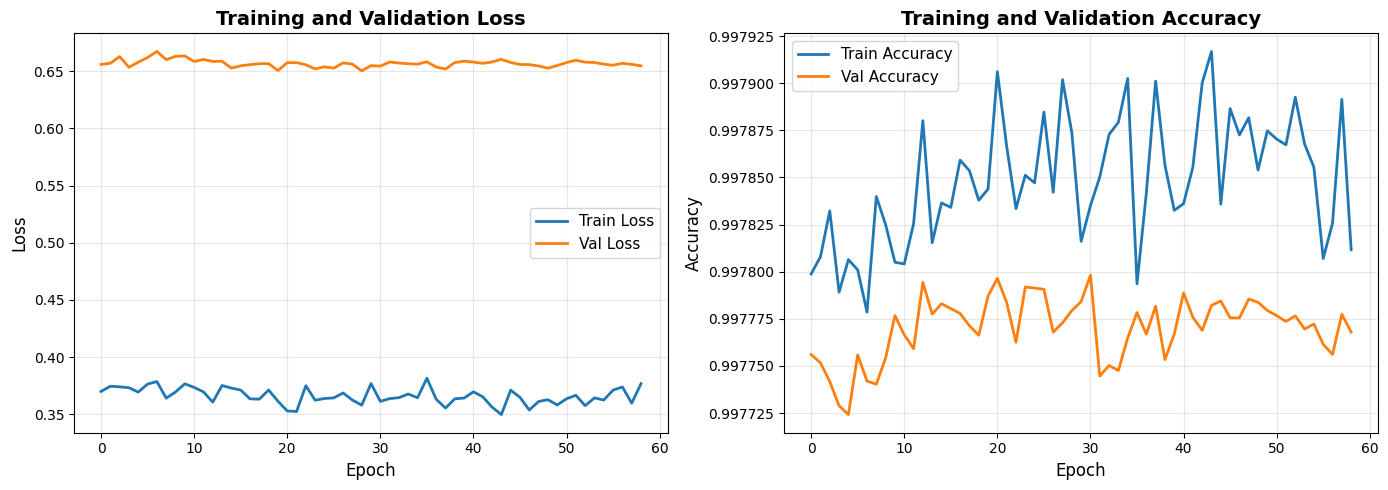

In [31]:
print("Training Attention U-Net...")
history_attention_unet = attention_unet_model.fit(
    train_dataset,
    validation_data=val_dataset,
    epochs=Config.EPOCHS,
    callbacks=callbacks_list,
    verbose=1
)

print("\nTraining HRNet...")
history_hrnet = hrnet_model.fit(
    train_dataset,
    validation_data=val_dataset,
    epochs=Config.EPOCHS,
    callbacks=callbacks_list,
    verbose=1
)

plot_training_history(history_attention_unet)
plot_training_history(history_hrnet)

In [32]:
# TTA Evaluation (run after training is complete)
best_thresh_unet_tta, best_metrics_unet_tta = multi_threshold_evaluation_tta(
    attention_unet_model, val_dataset_obj
)
best_thresh_hrnet_tta, best_metrics_hrnet_tta = multi_threshold_evaluation_tta(
    hrnet_model, val_dataset_obj
)

print("\n--- COMPARISON ---")
print(f"Attention U-Net  plain : Dice={best_metrics_unet['dice']:.4f}")
print(f"Attention U-Net  TTA   : Dice={best_metrics_unet_tta['dice']:.4f}")
print(f"HRNet            plain : Dice={best_metrics_hrnet['dice']:.4f}")
print(f"HRNet            TTA   : Dice={best_metrics_hrnet_tta['dice']:.4f}")


MULTI-THRESHOLD EVALUATION WITH TTA
Generating TTA predictions (slower — be patient)...

Threshold   Dice      IoU       Recall    Precision F1        
------------------------------------------------------------
0.10        0.4967    0.3304    0.6615    0.3977    0.4967    
0.15        0.5883    0.4167    0.6151    0.5637    0.5883    
0.20        0.5916    0.4200    0.5995    0.5839    0.5916    
0.25        0.6014    0.4300    0.5767    0.6283    0.6014    
0.30        0.5987    0.4272    0.5560    0.6484    0.5987    
0.35        0.5962    0.4247    0.5417    0.6630    0.5962    
0.40        0.5925    0.4209    0.5143    0.6986    0.5925    
0.45        0.5838    0.4122    0.4962    0.7091    0.5838    
0.50        0.3730    0.2293    0.2501    0.7336    0.3730    
0.55        0.2177    0.1222    0.1302    0.6650    0.2177    
0.60        0.2080    0.1161    0.1230    0.6720    0.2080    
0.65        0.1793    0.0985    0.1033    0.6767    0.1793    
0.70        0.1712    0.0936   

In [33]:
# --- KULLANIM ---
# Hangi modeli ve dataseti kullanmak istiyorsan buraya yaz
# Öneri: Validation setini kullan ki modelin görmediği verideki başarısını gör.

save_prediction_results(
    model=attention_unet_model,       # Eğittiğin model ismi
    dataset_obj=val_dataset_obj,      # Validation datasetin
    output_folder="AITex_Sonuclar",   # Klasör ismi
    num_samples=50,                   # Kaç resim kaydedilsin?
    threshold=0.5                     # Hangi değerin üstü hata sayılsın?
)

💾 Kayıt İşlemi Başladı... Hedef Klasör: AITex_Sonuclar
   -> 10 adet görsel işlendi...
   -> 20 adet görsel işlendi...
   -> 30 adet görsel işlendi...
   -> 40 adet görsel işlendi...
   -> 50 adet görsel işlendi...

✅ İŞLEM TAMAM! Toplam 50 görsel 'AITex_Sonuclar' içine kaydedildi.
📦 'AITex_Sonuclar.zip' dosyası oluşturuldu. İndirebilirsiniz!


In [34]:
# --- KULLANIM ---

# 1. Attention U-Net için Kaydet (Eğitim değişkenin adı 'history_unet' ise)
# Eğer değişken adın farklıysa (örneğin sadece 'history') onu yaz.
if 'history_unet' in globals():
    save_training_metrics(history_unet, model_name="Attention_UNet")
elif 'history' in globals(): # Genelde sadece history kullanılır
    save_training_metrics(history, model_name="Attention_UNet")
else:
    print("⚠️ 'history' değişkeni bulunamadı. Eğitimi 'history = model.fit(...)' şeklinde başlattığından emin ol.")

# 2. HRNet için Kaydet (Varsa)
if 'history_hrnet' in globals():
    save_training_metrics(history_hrnet, model_name="HRNet")

# 3. Tüm dosyaları indirmek için zip yap
import shutil
shutil.make_archive("Model_Metrikleri", 'zip', "Model_Metrikleri")
print("\n📦 'Model_Metrikleri.zip' hazır! İndirebilirsin.")

⚠️ 'history' değişkeni bulunamadı. Eğitimi 'history = model.fit(...)' şeklinde başlattığından emin ol.
📊 Metrik Kaydı Başladı... Hedef: Model_Metrikleri
   🌟 En İyi Epoch: 29 (Val Dice: 0.3612)
   💾 Tablo kaydedildi: Model_Metrikleri/HRNet_training_log.csv
   📈 Grafik kaydedildi: Model_Metrikleri/HRNet_metrics_plot.png
--------------------------------------------------

📦 'Model_Metrikleri.zip' hazır! İndirebilirsin.


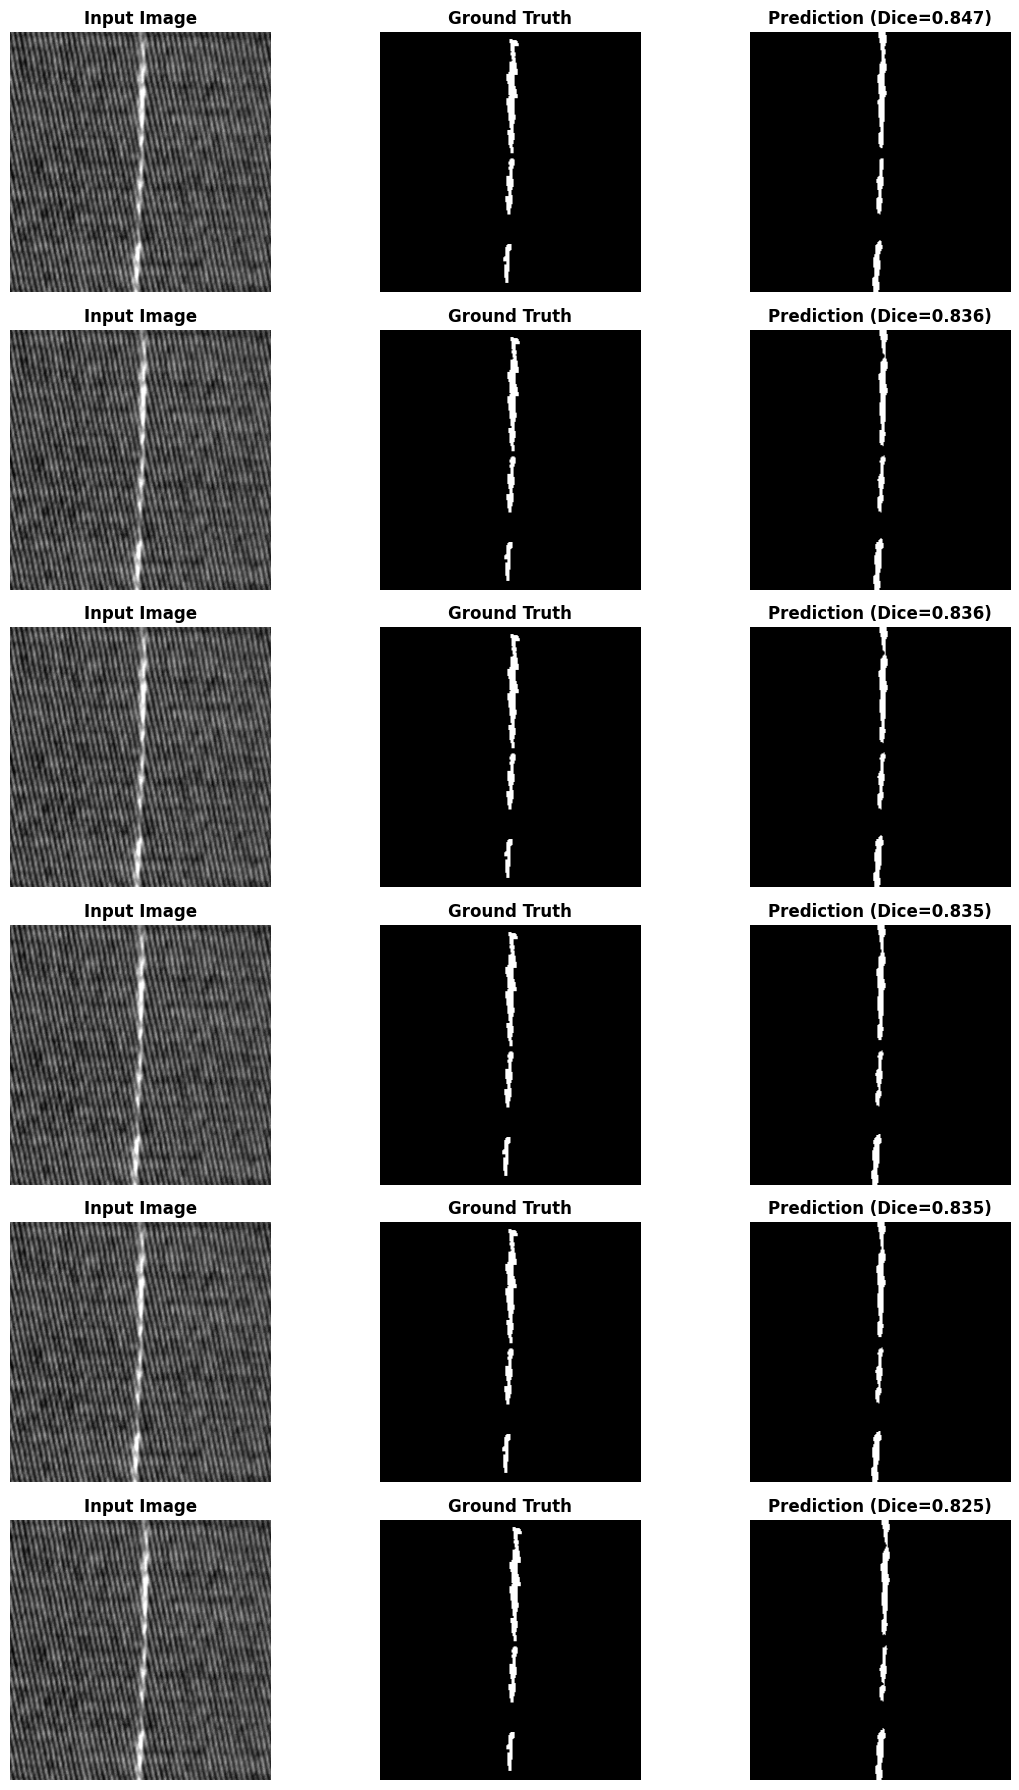

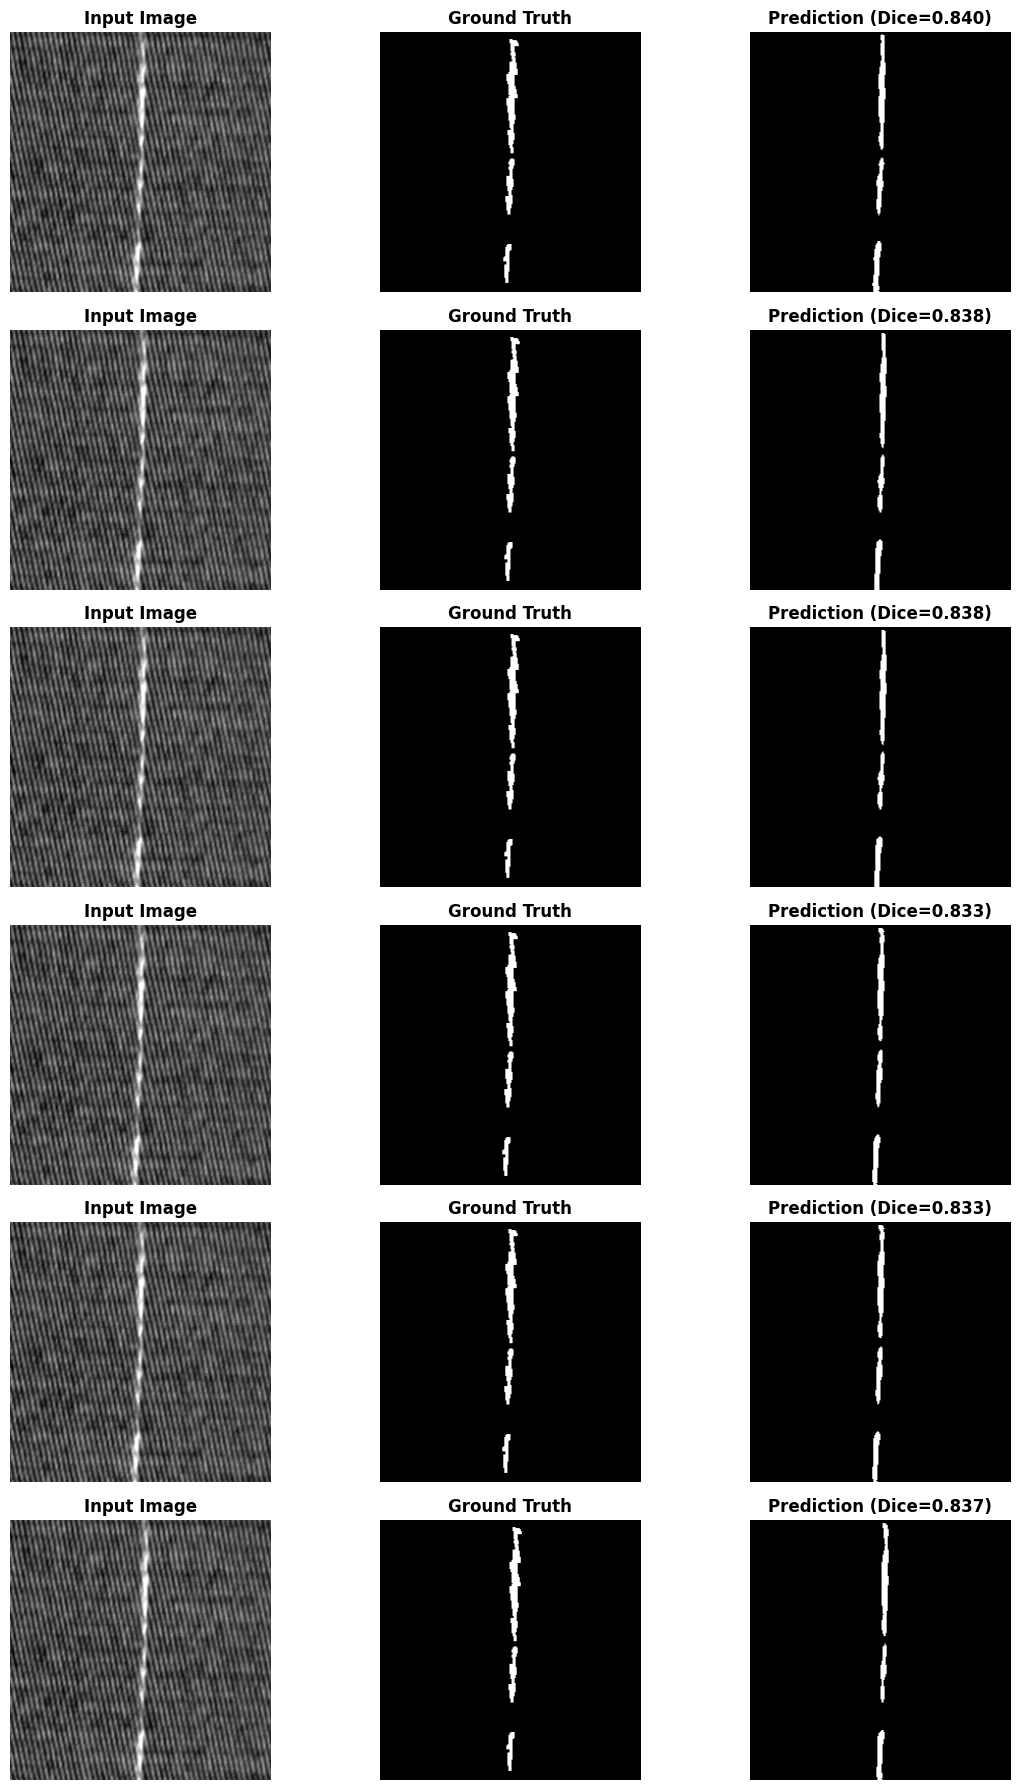

In [35]:
visualize_predictions(attention_unet_model, val_dataset, num_samples=6, threshold=best_thresh_unet)
visualize_predictions(hrnet_model, val_dataset, num_samples=6, threshold=best_thresh_hrnet)